In [25]:
!git clone https://github.com/binance/binance-public-data.git

Cloning into 'binance-public-data'...
remote: Enumerating objects: 304, done.
remote: Counting objects: 100% (176/176), done.
remote: Compressing objects: 100% (104/104), done.
remote: Total 304 (delta 135), reused 72 (delta 72), pack-reused 128 (from 2)
Receiving objects: 100% (304/304), 6.51 MiB | 37.66 MiB/s, done.
Resolving deltas: 100% (166/166), done.


In [26]:
%cd binance-public-data/python

/Users/shawnjune/Desktop/University_of_Virginia_(UVA)/School_of_Data_Science/Courses/Fall_2026/4 Data Engineering I/ML_I/binance-public-data/python/binance-public-data/python/binance-public-data/python


In [27]:
!pip install -r requirements.txt

In [28]:
!python3 download-kline.py \
-t spot \
-s BTCUSDT ETHUSDT XRPUSDT SOLUSDT \
-i 1d \
-startDate 2021-01-01 \
-endDate 2025-12-31 \
-skip-daily 1

Found 4 symbols
[1/4] - start download monthly BTCUSDT klines 

File Download: /Users/shawnjune/Desktop/University_of_Virginia_(UVA)/School_of_Data_Science/Courses/Fall_2026/4 Data Engineering I/ML_I/binance-public-data/python/binance-public-data/python/binance-public-data/python/data/spot/monthly/klines/BTCUSDT/1d/2021-01-01_2025-12-31/BTCUSDT-1d-2021-01.zip
[##################################################]
File Download: /Users/shawnjune/Desktop/University_of_Virginia_(UVA)/School_of_Data_Science/Courses/Fall_2026/4 Data Engineering I/ML_I/binance-public-data/python/binance-public-data/python/binance-public-data/python/data/spot/monthly/klines/BTCUSDT/1d/2021-01-01_2025-12-31/BTCUSDT-1d-2021-02.zip
[##################################################]
File Download: /Users/shawnjune/Desktop/University_of_Virginia_(UVA)/School_of_Data_Science/Courses/Fall_2026/4 Data Engineering I/ML_I/binance-public-data/python/binance-public-data/python/binance-public-data/python/data/spot/monthly

In [29]:
%pip install coinmetrics-api-client
from coinmetrics.api_client import CoinMetricsClient

client = CoinMetricsClient()

assets = ["btc", "eth", "xrp", "sol"]

metrics = [
    "TxCnt",
    "AdrActCnt"
]

data = client.get_asset_metrics(
    assets=assets,
    metrics=metrics,
    frequency="1d",
    start_time="2021-01-01",
    end_time="2025-12-31"
)

# SOL is not accessible with these API credentials for the requested metrics
assets = ["btc", "eth", "xrp"]

data = client.get_asset_metrics(
    assets=assets,
    metrics=metrics,
    frequency="1d",
    start_time="2021-01-01",
    end_time="2025-12-31"
)

df = data.to_dataframe()

df.head()

Note: you may need to restart the kernel to use updated packages.


,asset,time,TxCnt,AdrActCnt
0,btc,2021-01-01 00:00:00+00:00,261318.0,1001890.0
1,btc,2021-01-02 00:00:00+00:00,297595.0,1140633.0
2,btc,2021-01-03 00:00:00+00:00,359641.0,1184688.0
3,btc,2021-01-04 00:00:00+00:00,370865.0,1270082.0
4,btc,2021-01-05 00:00:00+00:00,355008.0,1230529.0


In [30]:
import pandas as pd
from coinmetrics.api_client import CoinMetricsClient

client = CoinMetricsClient()

assets = ["btc", "eth", "xrp", "sol"]

candidate_metrics = [
    "TxCnt",        # Transaction count
    "AdrActCnt",    # Active addresses
    "FeeTotNtv",    # Total native network fees
    "AdrNewCnt",    # New addresses
    "SplyCur"       # Current supply
]

results = []

for asset in assets:
    for metric in candidate_metrics:
        try:
            test = client.get_asset_metrics(
                assets=[asset],
                metrics=[metric],
                frequency="1d",
                start_time="2025-01-01",
                end_time="2025-01-03",
                limit_per_asset=1
            ).to_dataframe()

            results.append({
                "asset": asset.upper(),
                "metric": metric,
                "available": True
            })

        except Exception:
            results.append({
                "asset": asset.upper(),
                "metric": metric,
                "available": False
            })

availability = pd.DataFrame(results)

availability.pivot(
    index="metric",
    columns="asset",
    values="available"
)

/var/folders/4z/31j6h5x14v57pl5d5jgsxvwm0000gn/T/ipykernel_41447/2154937767.py:21: UserWarning: Parameters ['limit_per_asset'] are not compatible with format='json_stream'. Reverting to format='json'.
  test = client.get_asset_metrics(


asset,BTC,ETH,SOL,XRP
metric,,,,
AdrActCnt,True,True,False,True
AdrNewCnt,False,False,False,False
FeeTotNtv,True,True,False,True
SplyCur,True,True,False,True
TxCnt,True,True,False,True


In [31]:
from coinmetrics.api_client import CoinMetricsClient

client = CoinMetricsClient()

assets = ["btc", "eth", "xrp"]

metrics = [
    "TxCnt",
    "AdrActCnt",
    "FeeTotNtv",
    "SplyCur"
]

data = client.get_asset_metrics(
    assets=assets,
    metrics=metrics,
    frequency="1d",
    start_time="2021-01-01",
    end_time="2025-12-31"
)

onchain_df = data.to_dataframe()

onchain_df.head()

,asset,time,TxCnt,AdrActCnt,FeeTotNtv,SplyCur,SplyCur-status-time,SplyCur-status
0,btc,2021-01-01 00:00:00+00:00,261318.0,1001890.0,48.651326,18587827.692477,NaT,<NA>
1,btc,2021-01-02 00:00:00+00:00,297595.0,1140633.0,81.970521,18588771.442477,NaT,<NA>
2,btc,2021-01-03 00:00:00+00:00,359641.0,1184688.0,85.005302,18589758.942477,NaT,<NA>
3,btc,2021-01-04 00:00:00+00:00,370865.0,1270082.0,109.547478,18590840.192477,NaT,<NA>
4,btc,2021-01-05 00:00:00+00:00,355008.0,1230529.0,114.15545,18591821.442412,NaT,<NA>


In [32]:
onchain_df.shape

(5478, 8)

In [33]:
onchain_df.tail()

,asset,time,TxCnt,AdrActCnt,FeeTotNtv,SplyCur,SplyCur-status-time,SplyCur-status
5473,xrp,2025-12-27 00:00:00+00:00,1830702.0,40583.0,346.465428,99985669611.468933,NaT,<NA>
5474,xrp,2025-12-28 00:00:00+00:00,1674663.0,40169.0,371.588096,99985669239.880844,NaT,<NA>
5475,xrp,2025-12-29 00:00:00+00:00,1852929.0,43792.0,466.029359,99985668773.851486,NaT,<NA>
5476,xrp,2025-12-30 00:00:00+00:00,2077558.0,60169.0,630.243647,99985668143.607834,NaT,<NA>
5477,xrp,2025-12-31 00:00:00+00:00,2116802.0,51038.0,478.157645,99985667665.450195,NaT,<NA>


In [34]:
onchain_df.to_csv(
    "cryptolens_onchain_btc_eth_xrp_2021_2025.csv",
    index=False
)

In [35]:
onchain_df.shape

(5478, 8)

In [36]:
onchain_df.tail()

,asset,time,TxCnt,AdrActCnt,FeeTotNtv,SplyCur,SplyCur-status-time,SplyCur-status
5473,xrp,2025-12-27 00:00:00+00:00,1830702.0,40583.0,346.465428,99985669611.468933,NaT,<NA>
5474,xrp,2025-12-28 00:00:00+00:00,1674663.0,40169.0,371.588096,99985669239.880844,NaT,<NA>
5475,xrp,2025-12-29 00:00:00+00:00,1852929.0,43792.0,466.029359,99985668773.851486,NaT,<NA>
5476,xrp,2025-12-30 00:00:00+00:00,2077558.0,60169.0,630.243647,99985668143.607834,NaT,<NA>
5477,xrp,2025-12-31 00:00:00+00:00,2116802.0,51038.0,478.157645,99985667665.450195,NaT,<NA>


In [37]:
onchain_df.to_csv(
    "cryptolens_onchain_btc_eth_xrp_2021_2025.csv",
    index=False
)

In [38]:
import os
os.path.exists("cryptolens_onchain_btc_eth_xrp_2021_2025.csv")

True

In [39]:
onchain_df.head()

,asset,time,TxCnt,AdrActCnt,FeeTotNtv,SplyCur,SplyCur-status-time,SplyCur-status
0,btc,2021-01-01 00:00:00+00:00,261318.0,1001890.0,48.651326,18587827.692477,NaT,<NA>
1,btc,2021-01-02 00:00:00+00:00,297595.0,1140633.0,81.970521,18588771.442477,NaT,<NA>
2,btc,2021-01-03 00:00:00+00:00,359641.0,1184688.0,85.005302,18589758.942477,NaT,<NA>
3,btc,2021-01-04 00:00:00+00:00,370865.0,1270082.0,109.547478,18590840.192477,NaT,<NA>
4,btc,2021-01-05 00:00:00+00:00,355008.0,1230529.0,114.15545,18591821.442412,NaT,<NA>


In [40]:
onchain_df.shape

(5478, 8)

In [41]:
onchain_df.tail()

,asset,time,TxCnt,AdrActCnt,FeeTotNtv,SplyCur,SplyCur-status-time,SplyCur-status
5473,xrp,2025-12-27 00:00:00+00:00,1830702.0,40583.0,346.465428,99985669611.468933,NaT,<NA>
5474,xrp,2025-12-28 00:00:00+00:00,1674663.0,40169.0,371.588096,99985669239.880844,NaT,<NA>
5475,xrp,2025-12-29 00:00:00+00:00,1852929.0,43792.0,466.029359,99985668773.851486,NaT,<NA>
5476,xrp,2025-12-30 00:00:00+00:00,2077558.0,60169.0,630.243647,99985668143.607834,NaT,<NA>
5477,xrp,2025-12-31 00:00:00+00:00,2116802.0,51038.0,478.157645,99985667665.450195,NaT,<NA>


In [42]:
onchain_df.columns

Index(['asset', 'time', 'TxCnt', 'AdrActCnt', 'FeeTotNtv', 'SplyCur',
       'SplyCur-status-time', 'SplyCur-status'],
      dtype='object')

In [43]:
print(onchain_df["asset"].value_counts())

print("\nEarliest date:")
print(onchain_df["time"].min())

print("\nLatest date:")
print(onchain_df["time"].max())

asset
btc    1826
eth    1826
xrp    1826
Name: count, dtype: Int64

Earliest date:
2021-01-01 00:00:00+00:00

Latest date:
2025-12-31 00:00:00+00:00


In [44]:
# Make a clean working copy
clean_onchain = onchain_df.copy()

# Keep only the columns we actually need
clean_onchain = clean_onchain[
    ["asset", "time", "TxCnt", "AdrActCnt", "FeeTotNtv", "SplyCur"]
]

# Convert time to datetime
clean_onchain["time"] = pd.to_datetime(clean_onchain["time"])

# Convert blockchain metrics to numeric
numeric_cols = ["TxCnt", "AdrActCnt", "FeeTotNtv", "SplyCur"]

for col in numeric_cols:
    clean_onchain[col] = pd.to_numeric(
        clean_onchain[col],
        errors="coerce"
    )

clean_onchain.head()

,asset,time,TxCnt,AdrActCnt,FeeTotNtv,SplyCur
0,btc,2021-01-01 00:00:00+00:00,261318.0,1001890.0,48.651326,18587827.692477
1,btc,2021-01-02 00:00:00+00:00,297595.0,1140633.0,81.970521,18588771.442477
2,btc,2021-01-03 00:00:00+00:00,359641.0,1184688.0,85.005302,18589758.942477
3,btc,2021-01-04 00:00:00+00:00,370865.0,1270082.0,109.547478,18590840.192477
4,btc,2021-01-05 00:00:00+00:00,355008.0,1230529.0,114.15545,18591821.442412


In [45]:
clean_onchain.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5478 entries, 0 to 5477
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype              
---  ------     --------------  -----              
 0   asset      5478 non-null   string             
 1   time       5478 non-null   datetime64[ns, UTC]
 2   TxCnt      5478 non-null   Float64            
 3   AdrActCnt  5478 non-null   Float64            
 4   FeeTotNtv  5478 non-null   Float64            
 5   SplyCur    5478 non-null   Float64            
dtypes: Float64(4), datetime64[ns, UTC](1), string(1)
memory usage: 278.3 KB


In [46]:
duplicates = clean_onchain.duplicated(
    subset=["asset", "time"]
).sum()

print("Duplicate asset/date rows:", duplicates)

Duplicate asset/date rows: 0


In [47]:
clean_onchain.groupby("asset")[
    ["TxCnt", "AdrActCnt", "FeeTotNtv", "SplyCur"]
].describe()

TxCnt                                                                  \
        count            mean            std       min         25%        50%   
asset                                                                           
btc    1826.0   377898.125411  138488.695142  123967.0   269717.25   334199.0   
eth    1826.0  1208726.844469  184443.936065  742785.0  1089927.75  1174545.5   
xrp    1826.0  1520924.869113   695312.92961  612171.0   1123276.5  1326729.5   

                             AdrActCnt                 ...    FeeTotNtv  \
              75%        max     count           mean  ...          75%   
asset                                                  ...                
btc     463760.75   928131.0    1826.0  869887.302848  ...    33.253679   
eth    1277856.75  2230801.0    1826.0  571990.072289  ...  5245.421036   
xrp     1786408.5  7226301.0    1826.0   59493.952903  ...  3255.856622   

                    SplyCur                                      \
                max   count                mean             std   
asset                                                             
btc     1206.466584  1826.0     19370775.578255   420916.111625   
eth    81747.493962  1826.0    119481485.052825  1721300.431641   
xrp    60069.220172  1826.0  99988323093.067947  1547928.381466   

                                                                   \
                      min                 25%                 50%   
asset                                                               
btc       18587827.692477      19001215.61847     19418677.494308   
eth      114093437.799373    118677528.385622    120235414.268249   
xrp    99985667665.450195  99987066573.055115  99988554993.318787   

                                              
                     75%                 max  
asset                                         
btc      19761407.834647     19969701.159965  
eth     120519724.928878    121337037.110552  
xrp    99989509874.74559  99990723366.115128  

[3 rows x 32 columns]

In [48]:
# Sort data first
clean_onchain = clean_onchain.sort_values(["asset", "time"]).copy()

# Create blockchain activity change features
clean_onchain["TxCnt_7d_pct_change"] = (
    clean_onchain.groupby("asset")["TxCnt"]
    .pct_change(periods=7)
)

clean_onchain["AdrActCnt_7d_pct_change"] = (
    clean_onchain.groupby("asset")["AdrActCnt"]
    .pct_change(periods=7)
)

clean_onchain["FeeTotNtv_7d_pct_change"] = (
    clean_onchain.groupby("asset")["FeeTotNtv"]
    .pct_change(periods=7)
)

# 30-day rolling averages
clean_onchain["TxCnt_30d_avg"] = (
    clean_onchain.groupby("asset")["TxCnt"]
    .transform(lambda x: x.rolling(30).mean())
)

clean_onchain["AdrActCnt_30d_avg"] = (
    clean_onchain.groupby("asset")["AdrActCnt"]
    .transform(lambda x: x.rolling(30).mean())
)

clean_onchain.head(35)

,asset,time,TxCnt,AdrActCnt,FeeTotNtv,SplyCur,TxCnt_7d_pct_change,AdrActCnt_7d_pct_change,FeeTotNtv_7d_pct_change,TxCnt_30d_avg,AdrActCnt_30d_avg
0,btc,2021-01-01 00:00:00+00:00,261318.0,1001890.0,48.651326,18587827.692477,<NA>,<NA>,<NA>,NaN,NaN
1,btc,2021-01-02 00:00:00+00:00,297595.0,1140633.0,81.970521,18588771.442477,<NA>,<NA>,<NA>,NaN,NaN
2,btc,2021-01-03 00:00:00+00:00,359641.0,1184688.0,85.005302,18589758.942477,<NA>,<NA>,<NA>,NaN,NaN
3,btc,2021-01-04 00:00:00+00:00,370865.0,1270082.0,109.547478,18590840.192477,<NA>,<NA>,<NA>,NaN,NaN
4,btc,2021-01-05 00:00:00+00:00,355008.0,1230529.0,114.15545,18591821.442412,<NA>,<NA>,<NA>,NaN,NaN
5,btc,2021-01-06 00:00:00+00:00,398455.0,1344921.0,128.441558,18592927.692412,<NA>,<NA>,<NA>,NaN,NaN
6,btc,2021-01-07 00:00:00+00:00,402123.0,1292297.0,122.797172,18593977.692384,<NA>,<NA>,<NA>,NaN,NaN
7,btc,2021-01-08 00:00:00+00:00,358440.0,1237271.0,135.874671,18594902.692384,0.371662,0.234937,1.792826,NaN,NaN
8,btc,2021-01-09 00:00:00+00:00,318922.0,1094947.0,108.180619,18595771.442384,0.071665,-0.040053,0.31975,NaN,NaN
9,btc,2021-01-10 00:00:00+00:00,332604.0,1177151.0,91.962467,18596765.192384,-0.075178,-0.006362,0.081844,NaN,NaN


In [49]:
clean_onchain[
    [
        "asset",
        "time",
        "TxCnt_7d_pct_change",
        "AdrActCnt_7d_pct_change",
        "FeeTotNtv_7d_pct_change",
        "TxCnt_30d_avg",
        "AdrActCnt_30d_avg"
    ]
].tail()

,asset,time,TxCnt_7d_pct_change,AdrActCnt_7d_pct_change,FeeTotNtv_7d_pct_change,TxCnt_30d_avg,AdrActCnt_30d_avg
5473,xrp,2025-12-27 00:00:00+00:00,0.165208,-0.011858,0.006011,1.883830e+06,45147.900000
5474,xrp,2025-12-28 00:00:00+00:00,0.117132,-0.001243,0.112051,1.872363e+06,45027.866667
5475,xrp,2025-12-29 00:00:00+00:00,0.03627,-0.06062,-0.154443,1.864316e+06,44717.900000
5476,xrp,2025-12-30 00:00:00+00:00,0.160402,0.247259,0.268444,1.867659e+06,45149.000000
5477,xrp,2025-12-31 00:00:00+00:00,0.264042,0.044576,0.128632,1.867973e+06,45107.800000


In [50]:
# Create 30-day rolling z-scores for abnormal blockchain activity

def rolling_zscore(series, window=30):
    rolling_mean = series.rolling(window).mean()
    rolling_std = series.rolling(window).std()
    return (series - rolling_mean) / rolling_std

clean_onchain["TxCnt_30d_z"] = (
    clean_onchain.groupby("asset")["TxCnt"]
    .transform(lambda x: rolling_zscore(x, 30))
)

clean_onchain["AdrActCnt_30d_z"] = (
    clean_onchain.groupby("asset")["AdrActCnt"]
    .transform(lambda x: rolling_zscore(x, 30))
)

clean_onchain["FeeTotNtv_30d_z"] = (
    clean_onchain.groupby("asset")["FeeTotNtv"]
    .transform(lambda x: rolling_zscore(x, 30))
)

clean_onchain[
    [
        "asset",
        "time",
        "TxCnt_30d_z",
        "AdrActCnt_30d_z",
        "FeeTotNtv_30d_z"
    ]
].tail(10)

,asset,time,TxCnt_30d_z,AdrActCnt_30d_z,FeeTotNtv_30d_z
5468,xrp,2025-12-22 00:00:00+00:00,-0.79794,0.312545,-0.033392
5469,xrp,2025-12-23 00:00:00+00:00,-0.773484,0.821041,-0.424715
5470,xrp,2025-12-24 00:00:00+00:00,-1.35966,1.0088,-0.935413
5471,xrp,2025-12-25 00:00:00+00:00,-1.700609,-0.569759,-1.213907
5472,xrp,2025-12-26 00:00:00+00:00,-1.801427,-1.092618,-1.071845
5473,xrp,2025-12-27 00:00:00+00:00,-0.276796,-1.268628,-1.31668
5474,xrp,2025-12-28 00:00:00+00:00,-1.019746,-1.311667,-1.053765
5475,xrp,2025-12-29 00:00:00+00:00,-0.060154,-0.273825,-0.339294
5476,xrp,2025-12-30 00:00:00+00:00,1.091959,3.422935,0.837418
5477,xrp,2025-12-31 00:00:00+00:00,1.291704,1.371404,-0.26099


In [51]:
clean_onchain[
    ["TxCnt_30d_z", "AdrActCnt_30d_z", "FeeTotNtv_30d_z"]
].describe()

,TxCnt_30d_z,AdrActCnt_30d_z,FeeTotNtv_30d_z
count,5391.0,5391.0,5391.0
mean,0.018485,0.023217,-0.020186
std,1.120997,1.102812,1.119187
min,-3.823836,-3.75015,-3.454107
25%,-0.816575,-0.700425,-0.724992
50%,-0.012533,-0.116334,-0.272689
75%,0.750721,0.645377,0.449422
max,4.902854,5.291892,5.281045


In [52]:
# Create a combined On-Chain Activity Score

clean_onchain["OnChain_Activity_Score"] = (
    clean_onchain[
        [
            "TxCnt_30d_z",
            "AdrActCnt_30d_z",
            "FeeTotNtv_30d_z"
        ]
    ].mean(axis=1)
)

clean_onchain[
    [
        "asset",
        "time",
        "TxCnt_30d_z",
        "AdrActCnt_30d_z",
        "FeeTotNtv_30d_z",
        "OnChain_Activity_Score"
    ]
].tail(10)

,asset,time,TxCnt_30d_z,AdrActCnt_30d_z,FeeTotNtv_30d_z,OnChain_Activity_Score
5468,xrp,2025-12-22 00:00:00+00:00,-0.79794,0.312545,-0.033392,-0.172929
5469,xrp,2025-12-23 00:00:00+00:00,-0.773484,0.821041,-0.424715,-0.125719
5470,xrp,2025-12-24 00:00:00+00:00,-1.35966,1.0088,-0.935413,-0.428758
5471,xrp,2025-12-25 00:00:00+00:00,-1.700609,-0.569759,-1.213907,-1.161425
5472,xrp,2025-12-26 00:00:00+00:00,-1.801427,-1.092618,-1.071845,-1.321963
5473,xrp,2025-12-27 00:00:00+00:00,-0.276796,-1.268628,-1.31668,-0.954035
5474,xrp,2025-12-28 00:00:00+00:00,-1.019746,-1.311667,-1.053765,-1.128393
5475,xrp,2025-12-29 00:00:00+00:00,-0.060154,-0.273825,-0.339294,-0.224424
5476,xrp,2025-12-30 00:00:00+00:00,1.091959,3.422935,0.837418,1.784104
5477,xrp,2025-12-31 00:00:00+00:00,1.291704,1.371404,-0.26099,0.800706


In [53]:
clean_onchain["OnChain_Activity_Score"].describe()

count      5391.0
mean     0.007172
std      0.803996
min     -2.321811
25%      -0.53829
50%     -0.058276
75%      0.463303
max      4.047737
Name: OnChain_Activity_Score, dtype: Float64

In [54]:
clean_onchain.to_csv(
    "cryptolens_onchain_features_2021_2025.csv",
    index=False
)

In [55]:
# Select the features for unsupervised learning
cluster_features = [
    "TxCnt_7d_pct_change",
    "AdrActCnt_7d_pct_change",
    "FeeTotNtv_7d_pct_change",
    "TxCnt_30d_z",
    "AdrActCnt_30d_z",
    "FeeTotNtv_30d_z",
    "OnChain_Activity_Score"
]

cluster_df = clean_onchain[
    ["asset", "time"] + cluster_features
].dropna().copy()

cluster_df.head()

,asset,time,TxCnt_7d_pct_change,AdrActCnt_7d_pct_change,FeeTotNtv_7d_pct_change,TxCnt_30d_z,AdrActCnt_30d_z,FeeTotNtv_30d_z,OnChain_Activity_Score
29,btc,2021-01-30 00:00:00+00:00,0.032128,-0.0363,0.885238,-0.385209,-0.721196,1.017033,-0.02979
30,btc,2021-01-31 00:00:00+00:00,0.129759,0.059145,0.677965,-1.226277,-1.074346,-0.364746,-0.888456
31,btc,2021-02-01 00:00:00+00:00,-0.094233,-0.109265,0.30278,-1.301355,-1.717179,0.733034,-0.761834
32,btc,2021-02-02 00:00:00+00:00,0.081787,0.016631,0.77513,1.105648,0.658639,1.167311,0.977199
33,btc,2021-02-03 00:00:00+00:00,0.068499,0.073116,0.638109,0.615861,0.531362,0.78738,0.644868


In [56]:
cluster_df.shape

(5391, 9)

In [57]:
cluster_df["asset"].value_counts()

asset
btc    1797
eth    1797
xrp    1797
Name: count, dtype: Int64

In [58]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(
    cluster_df[cluster_features]
)

X_scaled

array([[ 0.07196329, -0.15622288,  0.74898377, ..., -0.67507553,
         0.92684738, -0.04597744],
       [ 0.5475387 ,  0.01202707,  0.5427534 , ..., -0.99533252,
        -0.30789501, -1.11407436],
       [-0.54355662, -0.28484522,  0.1694561 , ..., -1.57829022,
         0.67306847, -0.95656808],
       ...,
       [ 0.09213914, -0.19909442, -0.28546664, ..., -0.26937439,
        -0.28515149, -0.28808338],
       [ 0.69680273,  0.34363298,  0.1352929 , ...,  3.08305809,
         0.76634476,  2.21033038],
       [ 1.20164871, -0.0136542 , -0.00381652, ...,  1.22261333,
        -0.21518002,  0.98707923]], shape=(5391, 7))

In [59]:
scaled_df = pd.DataFrame(
    X_scaled,
    columns=cluster_features,
    index=cluster_df.index
)

scaled_df.head()

,TxCnt_7d_pct_change,AdrActCnt_7d_pct_change,FeeTotNtv_7d_pct_change,TxCnt_30d_z,AdrActCnt_30d_z,FeeTotNtv_30d_z,OnChain_Activity_Score
29,0.071963,-0.156223,0.748984,-0.360154,-0.675076,0.926847,-0.045977
30,0.547539,0.012027,0.542753,-1.110509,-0.995333,-0.307895,-1.114074
31,-0.543557,-0.284845,0.169456,-1.177490,-1.578290,0.673068,-0.956568
32,0.313858,-0.062917,0.639430,0.969908,0.576237,1.061134,1.206619
33,0.249130,0.036656,0.503098,0.532947,0.460815,0.721632,0.793232


In [60]:
scaled_df.describe().round(2)

,TxCnt_7d_pct_change,AdrActCnt_7d_pct_change,FeeTotNtv_7d_pct_change,TxCnt_30d_z,AdrActCnt_30d_z,FeeTotNtv_30d_z,OnChain_Activity_Score
count,5391.00,5391.00,5391.00,5391.00,5391.00,5391.00,5391.00
mean,0.00,-0.00,-0.00,0.00,-0.00,-0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-3.57,-1.77,-1.09,-3.43,-3.42,-3.07,-2.90
25%,-0.42,-0.23,-0.35,-0.74,-0.66,-0.63,-0.68
50%,-0.09,-0.09,-0.15,-0.03,-0.13,-0.23,-0.08
75%,0.25,0.06,0.09,0.65,0.56,0.42,0.57
max,22.75,38.78,30.45,4.36,4.78,4.74,5.03


In [61]:
from sklearn.decomposition import PCA

pca = PCA()

X_pca = pca.fit_transform(X_scaled)

explained_variance = pca.explained_variance_ratio_

explained_variance

array([0.44368905, 0.20210049, 0.13288961, 0.11117272, 0.06351183,
       0.0466363 , 0.        ])

In [62]:
import pandas as pd

pca_summary = pd.DataFrame({
    "Principal Component": [
        f"PC{i+1}" for i in range(len(explained_variance))
    ],
    "Explained Variance": explained_variance,
    "Cumulative Variance": explained_variance.cumsum()
})

pca_summary

,Principal Component,Explained Variance,Cumulative Variance
0,PC1,0.443689,0.443689
1,PC2,0.202100,0.645790
2,PC3,0.132890,0.778679
3,PC4,0.111173,0.889852
4,PC5,0.063512,0.953364
5,PC6,0.046636,1.000000
6,PC7,0.000000,1.000000


In [63]:
import numpy as np

n_components_80 = np.argmax(
    pca_summary["Cumulative Variance"].values >= 0.80
) + 1

print("Number of components needed for at least 80% variance:",
      n_components_80)

Number of components needed for at least 80% variance: 4


In [64]:
pca_final = PCA(n_components=n_components_80)

X_pca_final = pca_final.fit_transform(X_scaled)

pca_columns = [
    f"PC{i+1}" for i in range(n_components_80)
]

pca_df = pd.DataFrame(
    X_pca_final,
    columns=pca_columns,
    index=cluster_df.index
)

# Add asset and date back in
pca_df["asset"] = cluster_df["asset"].values
pca_df["time"] = cluster_df["time"].values

pca_df.head()

,PC1,PC2,PC3,PC4,asset,time
29,0.036023,1.318572,0.038939,0.399477,btc,2021-01-30
30,-1.290526,0.567892,-0.154520,1.346163,btc,2021-01-31
31,-1.636061,1.395983,0.139237,0.545525,btc,2021-02-01
32,1.930141,0.632307,-0.107093,-0.467964,btc,2021-02-02
33,1.311369,0.427921,0.042873,-0.236214,btc,2021-02-03


In [65]:
pca_df.shape

(5391, 6)

In [66]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Use only the PCA component columns
X_cluster = pca_df[pca_columns]

results = []

for k in range(2, 7):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_cluster)

    results.append({
        "k": k,
        "inertia": kmeans.inertia_,
        "silhouette_score": silhouette_score(X_cluster, labels)
    })

cluster_results = pd.DataFrame(results)

cluster_results

,k,inertia,silhouette_score
0,2,23957.605727,0.347914
1,3,20459.374458,0.287897
2,4,17696.478636,0.284446
3,5,15544.811183,0.261640
4,6,14067.700804,0.265377


In [67]:
best_k = cluster_results.loc[
    cluster_results["silhouette_score"].idxmax(),
    "k"
]

print("Best number of clusters based on silhouette score:", best_k)

Best number of clusters based on silhouette score: 2


In [68]:
final_kmeans = KMeans(
    n_clusters=int(best_k),
    random_state=42,
    n_init=10
)

pca_df["regime"] = final_kmeans.fit_predict(
    pca_df[pca_columns]
)

pca_df.head()

,PC1,PC2,PC3,PC4,asset,time,regime
29,0.036023,1.318572,0.038939,0.399477,btc,2021-01-30,1
30,-1.290526,0.567892,-0.154520,1.346163,btc,2021-01-31,1
31,-1.636061,1.395983,0.139237,0.545525,btc,2021-02-01,1
32,1.930141,0.632307,-0.107093,-0.467964,btc,2021-02-02,0
33,1.311369,0.427921,0.042873,-0.236214,btc,2021-02-03,0


In [69]:
pca_df["regime"].value_counts().sort_index()

regime
0    1952
1    3439
Name: count, dtype: int64

In [70]:
regime_df = cluster_df.copy()

regime_df["regime"] = pca_df["regime"].values

regime_summary = regime_df.groupby("regime")[cluster_features].mean().round(2)

regime_summary

,TxCnt_7d_pct_change,AdrActCnt_7d_pct_change,FeeTotNtv_7d_pct_change,TxCnt_30d_z,AdrActCnt_30d_z,FeeTotNtv_30d_z,OnChain_Activity_Score
regime,,,,,,,
0,0.13,0.21,0.46,1.0,0.76,0.71,0.82
1,-0.05,-0.04,-0.06,-0.54,-0.39,-0.44,-0.46


In [71]:
regime_output = cluster_df.copy()

regime_output["PC1"] = pca_df["PC1"].values
regime_output["PC2"] = pca_df["PC2"].values
regime_output["PC3"] = pca_df["PC3"].values
regime_output["PC4"] = pca_df["PC4"].values
regime_output["regime"] = pca_df["regime"].values

regime_output.to_csv(
    "cryptolens_blockchain_regimes_2021_2025.csv",
    index=False
)

regime_output.head()

,asset,time,TxCnt_7d_pct_change,AdrActCnt_7d_pct_change,FeeTotNtv_7d_pct_change,TxCnt_30d_z,AdrActCnt_30d_z,FeeTotNtv_30d_z,OnChain_Activity_Score,PC1,PC2,PC3,PC4,regime
29,btc,2021-01-30 00:00:00+00:00,0.032128,-0.0363,0.885238,-0.385209,-0.721196,1.017033,-0.02979,0.036023,1.318572,0.038939,0.399477,1
30,btc,2021-01-31 00:00:00+00:00,0.129759,0.059145,0.677965,-1.226277,-1.074346,-0.364746,-0.888456,-1.290526,0.567892,-0.154520,1.346163,1
31,btc,2021-02-01 00:00:00+00:00,-0.094233,-0.109265,0.30278,-1.301355,-1.717179,0.733034,-0.761834,-1.636061,1.395983,0.139237,0.545525,1
32,btc,2021-02-02 00:00:00+00:00,0.081787,0.016631,0.77513,1.105648,0.658639,1.167311,0.977199,1.930141,0.632307,-0.107093,-0.467964,0
33,btc,2021-02-03 00:00:00+00:00,0.068499,0.073116,0.638109,0.615861,0.531362,0.78738,0.644868,1.311369,0.427921,0.042873,-0.236214,0


In [72]:
# FINAL UNSUPERVISED ANALYSIS

final_features = [
    "TxCnt_7d_pct_change",
    "AdrActCnt_7d_pct_change",
    "FeeTotNtv_7d_pct_change",
    "TxCnt_30d_z",
    "AdrActCnt_30d_z",
    "FeeTotNtv_30d_z"
]

final_df = clean_onchain[
    ["asset", "time", "OnChain_Activity_Score"] + final_features
].dropna().copy()

from sklearn.preprocessing import StandardScaler

final_scaler = StandardScaler()

X_final_scaled = final_scaler.fit_transform(
    final_df[final_features]
)

final_df.shape

(5391, 9)

In [73]:
from sklearn.decomposition import PCA
import numpy as np
import pandas as pd

pca_all = PCA()
pca_all.fit(X_final_scaled)

final_pca_summary = pd.DataFrame({
    "Principal Component": [
        f"PC{i+1}" for i in range(len(final_features))
    ],
    "Explained Variance": pca_all.explained_variance_ratio_,
    "Cumulative Variance": pca_all.explained_variance_ratio_.cumsum()
})

final_pca_summary

,Principal Component,Explained Variance,Cumulative Variance
0,PC1,0.369463,0.369463
1,PC2,0.235585,0.605048
2,PC3,0.154916,0.759964
3,PC4,0.112623,0.872587
4,PC5,0.073005,0.945592
5,PC6,0.054408,1.000000


In [74]:
n_components_80 = np.argmax(
    final_pca_summary["Cumulative Variance"].values >= 0.80
) + 1

print(
    "Components needed for at least 80% variance:",
    n_components_80
)

Components needed for at least 80% variance: 4


In [75]:
pca_final = PCA(n_components=n_components_80)

X_pca_final = pca_final.fit_transform(X_final_scaled)

pca_columns = [
    f"PC{i+1}" for i in range(n_components_80)
]

pca_loadings = pd.DataFrame(
    pca_final.components_.T,
    index=final_features,
    columns=pca_columns
)

pca_loadings.round(3)

,PC1,PC2,PC3,PC4
TxCnt_7d_pct_change,0.463,-0.146,-0.527,-0.461
AdrActCnt_7d_pct_change,0.335,-0.335,0.616,-0.540
FeeTotNtv_7d_pct_change,0.281,0.635,0.231,-0.202
TxCnt_30d_z,0.535,-0.111,-0.397,0.235
AdrActCnt_30d_z,0.407,-0.371,0.344,0.591
FeeTotNtv_30d_z,0.377,0.560,0.119,0.223


In [76]:
pca_df_final = pd.DataFrame(
    X_pca_final,
    columns=pca_columns,
    index=final_df.index
)

pca_df_final["asset"] = final_df["asset"].values
pca_df_final["time"] = final_df["time"].values

pca_df_final.head()

,PC1,PC2,PC3,PC4,asset,time
29,0.073763,1.326674,0.059341,-0.376720,btc,2021-01-30
30,-0.706041,0.579976,-0.094025,-1.287014,btc,2021-01-31
31,-1.318095,1.375110,0.153552,-0.689291,btc,2021-02-01
32,1.458305,0.654540,-0.116921,0.566110,btc,2021-02-02
33,1.014304,0.445049,0.040396,0.322742,btc,2021-02-03


In [77]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X_cluster = pca_df_final[pca_columns]

results = []

for k in range(2, 7):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_cluster)

    results.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette_score": silhouette_score(
            X_cluster,
            labels
        )
    })

final_cluster_results = pd.DataFrame(results)

final_cluster_results

,k,inertia,silhouette_score
0,2,21711.181602,0.327191
1,3,18645.942551,0.295751
2,4,15772.655663,0.294868
3,5,14114.466981,0.277700
4,6,12589.487952,0.268755


In [78]:
best_k = int(
    final_cluster_results.loc[
        final_cluster_results["silhouette_score"].idxmax(),
        "k"
    ]
)

print("Best number of clusters:", best_k)

Best number of clusters: 2


In [79]:
final_kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

final_df["regime"] = final_kmeans.fit_predict(
    X_cluster
)

regime_profile = final_df.groupby("regime")[
    final_features + ["OnChain_Activity_Score"]
].mean().round(3)

regime_profile

,TxCnt_7d_pct_change,AdrActCnt_7d_pct_change,FeeTotNtv_7d_pct_change,TxCnt_30d_z,AdrActCnt_30d_z,FeeTotNtv_30d_z,OnChain_Activity_Score
regime,,,,,,,
0,-0.048,-0.037,-0.052,-0.516,-0.352,-0.391,-0.42
1,0.146,0.228,0.497,1.074,0.764,0.712,0.85


In [80]:
regime_name_map = {
    0: "Lower On-Chain Activity",
    1: "Elevated On-Chain Activity"
}

final_df["regime_label"] = final_df["regime"].map(
    regime_name_map
)

final_df["regime_label"].value_counts()

regime_label
Lower On-Chain Activity       3579
Elevated On-Chain Activity    1812
Name: count, dtype: int64

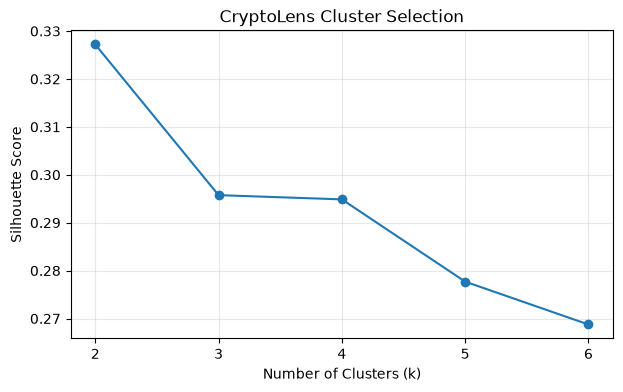

In [81]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))

plt.plot(
    final_cluster_results["k"],
    final_cluster_results["silhouette_score"],
    marker="o"
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("CryptoLens Cluster Selection")

plt.xticks(final_cluster_results["k"])
plt.grid(alpha=0.3)

plt.show()

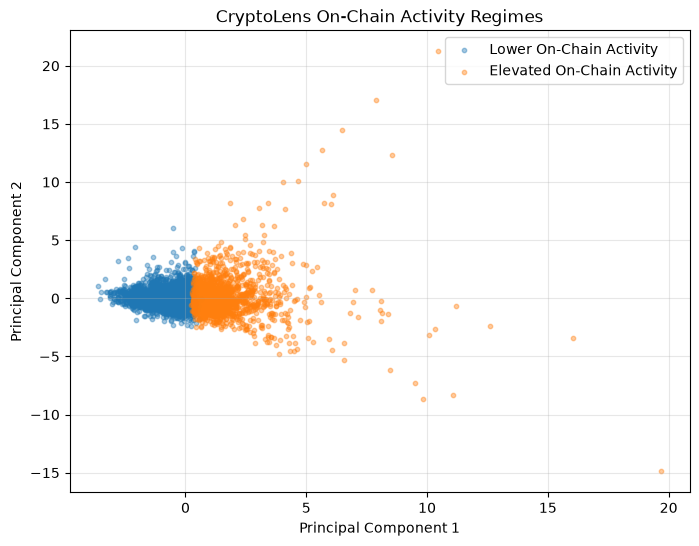

In [82]:
plt.figure(figsize=(8, 6))

for regime in sorted(final_df["regime"].unique()):
    mask = final_df["regime"] == regime

    plt.scatter(
        pca_df_final.loc[mask, "PC1"],
        pca_df_final.loc[mask, "PC2"],
        s=10,
        alpha=0.4,
        label=regime_name_map[regime]
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("CryptoLens On-Chain Activity Regimes")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [83]:
# FINAL EXPORTS

final_export = final_df.copy()

for pc in pca_columns:
    final_export[pc] = pca_df_final[pc].values

final_export.to_csv(
    "cryptolens_blockchain_regimes_2021_2025.csv",
    index=False
)

final_pca_summary.to_csv(
    "cryptolens_pca_summary.csv",
    index=False
)

pca_loadings.to_csv(
    "cryptolens_pca_loadings.csv"
)

regime_profile.to_csv(
    "cryptolens_regime_summary.csv"
)

final_cluster_results.to_csv(
    "cryptolens_cluster_selection.csv",
    index=False
)

print("All final CryptoLens blockchain outputs saved.")

All final CryptoLens blockchain outputs saved.


In [84]:
import os

final_files = [
    "cryptolens_blockchain_regimes_2021_2025.csv",
    "cryptolens_pca_summary.csv",
    "cryptolens_pca_loadings.csv",
    "cryptolens_regime_summary.csv",
    "cryptolens_cluster_selection.csv"
]

# Confirm all files exist
for file in final_files:
    print(file, ":", os.path.exists(file))

# Confirm final dataset is complete
assert len(final_export) == 5391
assert final_export["regime"].nunique() == 2
assert final_export["regime_label"].isna().sum() == 0
assert set(pca_columns).issubset(final_export.columns)

print("\nFinal dataset shape:", final_export.shape)

print("\nRegime counts:")
print(final_export["regime_label"].value_counts())

print("\nAll final CryptoLens blockchain checks passed.")

cryptolens_blockchain_regimes_2021_2025.csv : True
cryptolens_pca_summary.csv : True
cryptolens_pca_loadings.csv : True
cryptolens_regime_summary.csv : True
cryptolens_cluster_selection.csv : True

Final dataset shape: (5391, 15)

Regime counts:
regime_label
Lower On-Chain Activity       3579
Elevated On-Chain Activity    1812
Name: count, dtype: int64

All final CryptoLens blockchain checks passed.


## Bitcoin Market Leadership & Halving-Cycle Context

In [85]:
from pathlib import Path
import pandas as pd
import numpy as np
import zipfile

symbols = ["BTCUSDT", "ETHUSDT", "XRPUSDT", "SOLUSDT"]

kline_columns = [
    "open_time",
    "open",
    "high",
    "low",
    "close",
    "volume",
    "close_time",
    "quote_asset_volume",
    "number_of_trades",
    "taker_buy_base_volume",
    "taker_buy_quote_volume",
    "ignore"
]

market_frames = []

for symbol in symbols:

    files = list(
        Path(".").rglob(f"{symbol}-1d-*.zip")
    )

    print(symbol, "files found:", len(files))

    for file in files:

        df_temp = pd.read_csv(
            file,
            compression="zip",
            header=None,
            names=kline_columns
        )

        df_temp["symbol"] = symbol

        market_frames.append(df_temp)

market_df = pd.concat(
    market_frames,
    ignore_index=True
)

market_df.shape

BTCUSDT files found: 60
ETHUSDT files found: 60
XRPUSDT files found: 60
SOLUSDT files found: 60


(7304, 13)

In [86]:
# Clean Binance market data

market_df["open_time"] = pd.to_numeric(
    market_df["open_time"],
    errors="coerce"
)

# Binance historical timestamps may appear in milliseconds or microseconds
def convert_binance_time(x):
    if pd.isna(x):
        return pd.NaT

    if x > 100_000_000_000_000:
        return pd.to_datetime(x, unit="us", utc=True)
    else:
        return pd.to_datetime(x, unit="ms", utc=True)

market_df["date"] = market_df["open_time"].apply(
    convert_binance_time
)

numeric_cols = [
    "open",
    "high",
    "low",
    "close",
    "volume"
]

for col in numeric_cols:
    market_df[col] = pd.to_numeric(
        market_df[col],
        errors="coerce"
    )

market_df["asset"] = (
    market_df["symbol"]
    .str.replace("USDT", "", regex=False)
    .str.lower()
)

market_clean = (
    market_df[
        ["asset", "date", "open", "high", "low", "close", "volume"]
    ]
    .sort_values(["asset", "date"])
    .reset_index(drop=True)
)

market_clean.head()

,asset,date,open,high,low,close,volume
0,btc,2021-01-01 00:00:00+00:00,28923.63,29600.00,28624.57,29331.69,54182.925011
1,btc,2021-01-02 00:00:00+00:00,29331.70,33300.00,28946.53,32178.33,129993.873362
2,btc,2021-01-03 00:00:00+00:00,32176.45,34778.11,31962.99,33000.05,120957.566750
3,btc,2021-01-04 00:00:00+00:00,33000.05,33600.00,28130.00,31988.71,140899.885690
4,btc,2021-01-05 00:00:00+00:00,31989.75,34360.00,29900.00,33949.53,116049.997038


In [87]:
print("Rows per asset:")
print(market_clean["asset"].value_counts().sort_index())

print("\nEarliest date by asset:")
print(market_clean.groupby("asset")["date"].min())

print("\nLatest date by asset:")
print(market_clean.groupby("asset")["date"].max())

print("\nDuplicate asset/date rows:")
print(
    market_clean.duplicated(
        subset=["asset", "date"]
    ).sum()
)

print("\nMissing values:")
print(market_clean.isna().sum())

Rows per asset:
asset
btc    1826
eth    1826
sol    1826
xrp    1826
Name: count, dtype: int64

Earliest date by asset:
asset
btc   2021-01-01 00:00:00+00:00
eth   2021-01-01 00:00:00+00:00
sol   2021-01-01 00:00:00+00:00
xrp   2021-01-01 00:00:00+00:00
Name: date, dtype: datetime64[ns, UTC]

Latest date by asset:
asset
btc   2025-12-31 00:00:00+00:00
eth   2025-12-31 00:00:00+00:00
sol   2025-12-31 00:00:00+00:00
xrp   2025-12-31 00:00:00+00:00
Name: date, dtype: datetime64[ns, UTC]

Duplicate asset/date rows:
0

Missing values:
asset     0
date      0
open      0
high      0
low       0
close     0
volume    0
dtype: int64


In [88]:
# Calculate daily percentage returns for each cryptocurrency

market_clean["daily_return"] = (
    market_clean
    .groupby("asset")["close"]
    .pct_change()
)

# Put each cryptocurrency into its own column
returns_wide = market_clean.pivot(
    index="date",
    columns="asset",
    values="daily_return"
)

returns_wide.head()

asset,btc,eth,sol,xrp
date,,,,
2021-01-01 00:00:00+00:00,NaN,NaN,NaN,NaN
2021-01-02 00:00:00+00:00,0.097050,0.062628,-0.022909,-0.070833
2021-01-03 00:00:00+00:00,0.025536,0.263014,0.210012,0.021574
2021-01-04 00:00:00+00:00,-0.030647,0.064552,0.143716,0.045475
2021-01-05 00:00:00+00:00,0.061297,0.055817,-0.131398,-0.042096


In [89]:
# Correlation of daily returns, 2021-2025

return_correlations = returns_wide.corr()

print("Full return correlation matrix:")
display(return_correlations.round(3))

print("\nCorrelation with Bitcoin:")
print(
    return_correlations["btc"]
    .drop("btc")
    .sort_values(ascending=False)
    .round(3)
)

Full return correlation matrix:


asset,btc,eth,sol,xrp
asset,,,,
btc,1.000,0.806,0.602,0.565
eth,0.806,1.000,0.646,0.572
sol,0.602,0.646,1.000,0.482
xrp,0.565,0.572,0.482,1.000



Correlation with Bitcoin:
asset
eth    0.806
sol    0.602
xrp    0.565
Name: btc, dtype: float64


In [90]:
# 90-day rolling correlation with Bitcoin

rolling_corr = pd.DataFrame(
    index=returns_wide.index
)

for asset in ["eth", "sol", "xrp"]:
    rolling_corr[asset] = (
        returns_wide["btc"]
        .rolling(window=90)
        .corr(returns_wide[asset])
    )

rolling_corr.head(95)

,eth,sol,xrp
date,,,
2021-01-01 00:00:00+00:00,NaN,NaN,NaN
2021-01-02 00:00:00+00:00,NaN,NaN,NaN
2021-01-03 00:00:00+00:00,NaN,NaN,NaN
2021-01-04 00:00:00+00:00,NaN,NaN,NaN
2021-01-05 00:00:00+00:00,NaN,NaN,NaN
...,...,...,...
2021-04-01 00:00:00+00:00,0.688029,0.286301,0.260163
2021-04-02 00:00:00+00:00,0.681029,0.303558,0.284828
2021-04-03 00:00:00+00:00,0.735897,0.288229,0.289207


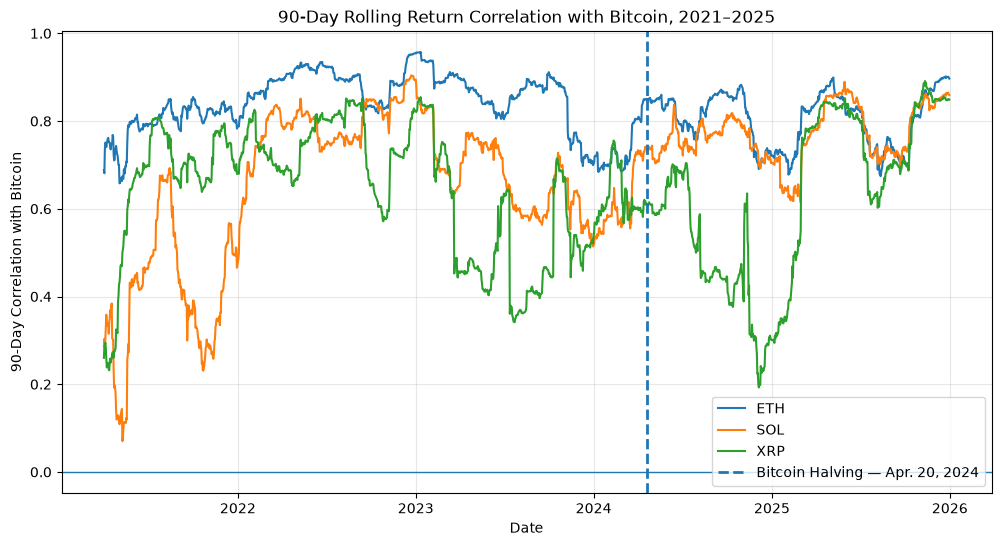

In [91]:
# Plot 90-day rolling correlations with Bitcoin

plt.figure(figsize=(12, 6))

for asset in ["eth", "sol", "xrp"]:
    plt.plot(
        rolling_corr.index,
        rolling_corr[asset],
        label=asset.upper()
    )

halving_date = pd.Timestamp(
    "2024-04-20",
    tz="UTC"
)

plt.axvline(
    halving_date,
    linestyle="--",
    linewidth=2,
    label="Bitcoin Halving — Apr. 20, 2024"
)

plt.axhline(
    0,
    linewidth=1
)

plt.xlabel("Date")
plt.ylabel("90-Day Correlation with Bitcoin")
plt.title(
    "90-Day Rolling Return Correlation with Bitcoin, 2021–2025"
)

plt.legend()
plt.grid(alpha=0.3)

plt.show()

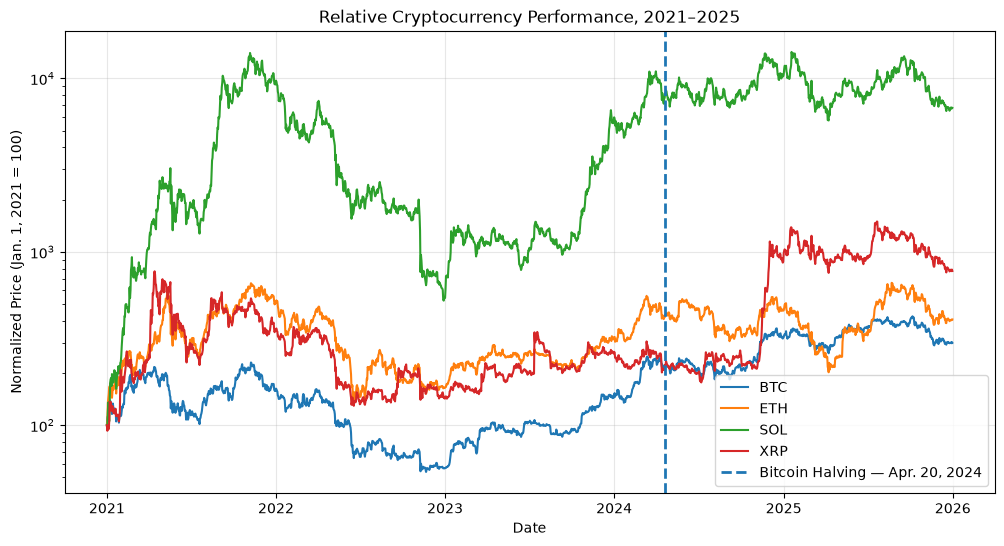

In [92]:
# Normalize all four cryptocurrencies to 100 at the start of 2021

close_wide = market_clean.pivot(
    index="date",
    columns="asset",
    values="close"
)

normalized_prices = (
    close_wide
    .div(close_wide.iloc[0])
    .mul(100)
)

plt.figure(figsize=(12, 6))

for asset in ["btc", "eth", "sol", "xrp"]:
    plt.plot(
        normalized_prices.index,
        normalized_prices[asset],
        label=asset.upper()
    )

plt.axvline(
    halving_date,
    linestyle="--",
    linewidth=2,
    label="Bitcoin Halving — Apr. 20, 2024"
)

plt.xlabel("Date")
plt.ylabel("Normalized Price (Jan. 1, 2021 = 100)")
plt.title(
    "Relative Cryptocurrency Performance, 2021–2025"
)

# Log scale prevents SOL's much larger relative moves
# from flattening the other three assets visually.
plt.yscale("log")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [93]:
# Compare on-chain activity regimes before vs. after the 2024 Bitcoin halving

halving_date = pd.Timestamp(
    "2024-04-20",
    tz="UTC"
)

final_df["halving_period"] = np.where(
    final_df["time"] < halving_date,
    "Pre-Halving",
    "Post-Halving"
)

halving_regime_summary = (
    final_df
    .groupby(["asset", "halving_period"])["regime_label"]
    .value_counts(normalize=True)
    .mul(100)
    .round(1)
    .rename("percent")
    .reset_index()
)

elevated_halving_summary = (
    halving_regime_summary[
        halving_regime_summary["regime_label"]
        == "Elevated On-Chain Activity"
    ]
)

elevated_halving_summary

,asset,halving_period,regime_label,percent
1,btc,Post-Halving,Elevated On-Chain Activity,32.2
3,btc,Pre-Halving,Elevated On-Chain Activity,37.8
5,eth,Post-Halving,Elevated On-Chain Activity,30.3
7,eth,Pre-Halving,Elevated On-Chain Activity,31.5
9,xrp,Post-Halving,Elevated On-Chain Activity,32.2
11,xrp,Pre-Halving,Elevated On-Chain Activity,34.7


In [94]:
# Percentage of each year spent in Elevated On-Chain Activity

final_df["year"] = final_df["time"].dt.year

annual_regime_summary = (
    final_df
    .assign(
        elevated=(
            final_df["regime_label"]
            == "Elevated On-Chain Activity"
        )
    )
    .groupby(["asset", "year"])["elevated"]
    .mean()
    .mul(100)
    .round(1)
    .reset_index(name="percent_elevated")
)

annual_regime_summary

,asset,year,percent_elevated
0,btc,2021,33.9
1,btc,2022,35.6
2,btc,2023,45.2
3,btc,2024,31.7
4,btc,2025,32.9
5,eth,2021,37.5
6,eth,2022,23.8
7,eth,2023,32.9
8,eth,2024,31.4
9,eth,2025,30.4


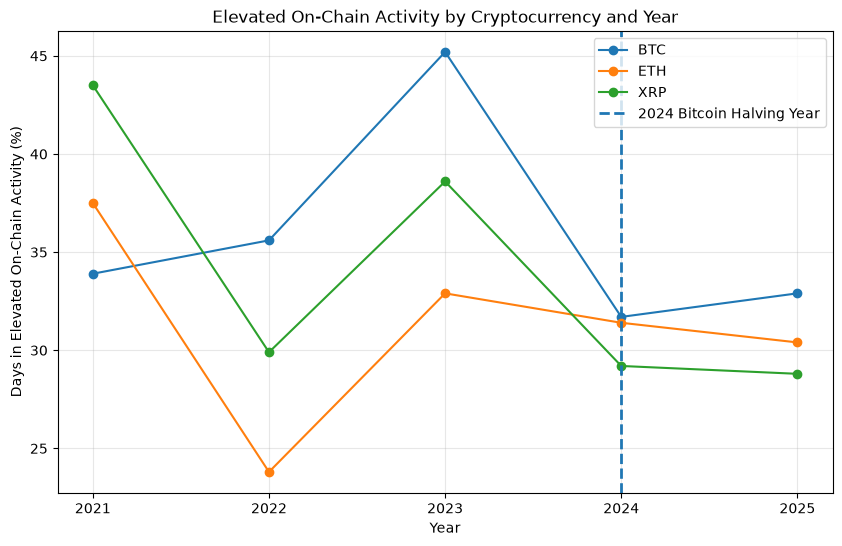

In [95]:
plt.figure(figsize=(10, 6))

for asset in ["btc", "eth", "xrp"]:
    asset_data = annual_regime_summary[
        annual_regime_summary["asset"] == asset
    ]

    plt.plot(
        asset_data["year"],
        asset_data["percent_elevated"],
        marker="o",
        label=asset.upper()
    )

plt.axvline(
    2024,
    linestyle="--",
    linewidth=2,
    label="2024 Bitcoin Halving Year"
)

plt.xlabel("Year")
plt.ylabel("Days in Elevated On-Chain Activity (%)")
plt.title(
    "Elevated On-Chain Activity by Cryptocurrency and Year"
)

plt.xticks([2021, 2022, 2023, 2024, 2025])
plt.legend()
plt.grid(alpha=0.3)

plt.show()

## Leakage-Safe Unsupervised Features for Predictive Modeling

In [96]:
# Split blockchain data chronologically:
# 2021–2024 = training
# 2025 = held-out test period

train_mask = final_df["time"] < pd.Timestamp(
    "2025-01-01",
    tz="UTC"
)

test_mask = ~train_mask

train_blockchain = final_df.loc[train_mask].copy()
test_blockchain = final_df.loc[test_mask].copy()

print("Training rows:", len(train_blockchain))
print("Testing rows:", len(test_blockchain))

print("\nTraining period:")
print(
    train_blockchain["time"].min(),
    "to",
    train_blockchain["time"].max()
)

print("\nTesting period:")
print(
    test_blockchain["time"].min(),
    "to",
    test_blockchain["time"].max()
)

Training rows: 4296
Testing rows: 1095

Training period:
2021-01-30 00:00:00+00:00 to 2024-12-31 00:00:00+00:00

Testing period:
2025-01-01 00:00:00+00:00 to 2025-12-31 00:00:00+00:00


In [97]:
# Fit preprocessing ONLY on 2021–2024 training data

leakage_scaler = StandardScaler()

X_train_scaled = leakage_scaler.fit_transform(
    train_blockchain[final_features]
)

# Apply training scaler to 2025 WITHOUT refitting
X_test_scaled = leakage_scaler.transform(
    test_blockchain[final_features]
)

# Determine PCA structure using training data only
leakage_pca_all = PCA()
leakage_pca_all.fit(X_train_scaled)

leakage_pca_summary = pd.DataFrame({
    "Principal Component": [
        f"PC{i+1}" for i in range(len(final_features))
    ],
    "Explained Variance":
        leakage_pca_all.explained_variance_ratio_,
    "Cumulative Variance":
        leakage_pca_all.explained_variance_ratio_.cumsum()
})

leakage_pca_summary

,Principal Component,Explained Variance,Cumulative Variance
0,PC1,0.376210,0.376210
1,PC2,0.233580,0.609790
2,PC3,0.150463,0.760253
3,PC4,0.112797,0.873050
4,PC5,0.074628,0.947678
5,PC6,0.052322,1.000000


In [98]:
# Keep enough PCs to explain at least 80% of TRAINING variance

leakage_n_components = np.argmax(
    leakage_pca_summary["Cumulative Variance"].values >= 0.80
) + 1

print(
    "Training-only components needed for at least 80% variance:",
    leakage_n_components
)

# Fit PCA ONLY on training data
leakage_pca = PCA(
    n_components=leakage_n_components
)

X_train_pca = leakage_pca.fit_transform(
    X_train_scaled
)

# Transform 2025 using training-fitted PCA
X_test_pca = leakage_pca.transform(
    X_test_scaled
)

print("Training PCA shape:", X_train_pca.shape)
print("Testing PCA shape:", X_test_pca.shape)

Training-only components needed for at least 80% variance: 4
Training PCA shape: (4296, 4)
Testing PCA shape: (1095, 4)


In [99]:
# Choose number of clusters using TRAINING data only

leakage_cluster_results = []

for k in range(2, 7):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    train_labels = model.fit_predict(
        X_train_pca
    )

    leakage_cluster_results.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette_score": silhouette_score(
            X_train_pca,
            train_labels
        )
    })

leakage_cluster_results = pd.DataFrame(
    leakage_cluster_results
)

leakage_cluster_results

,k,inertia,silhouette_score
0,2,17257.082481,0.327196
1,3,14910.560099,0.285027
2,4,12780.040339,0.300008
3,5,11227.396754,0.275183
4,6,9899.058459,0.274851


In [100]:
# Fit final K-means ONLY on training data

leakage_best_k = int(
    leakage_cluster_results.loc[
        leakage_cluster_results["silhouette_score"].idxmax(),
        "k"
    ]
)

leakage_kmeans = KMeans(
    n_clusters=leakage_best_k,
    random_state=42,
    n_init=10
)

# Learn clusters from 2021–2024
train_blockchain["regime"] = leakage_kmeans.fit_predict(
    X_train_pca
)

# Assign 2025 observations using the training-fitted model
test_blockchain["regime"] = leakage_kmeans.predict(
    X_test_pca
)

print("Best training-only k:", leakage_best_k)

print("\nTraining regime counts:")
print(train_blockchain["regime"].value_counts().sort_index())

print("\n2025 regime counts:")
print(test_blockchain["regime"].value_counts().sort_index())

Best training-only k: 2

Training regime counts:
regime
0    2816
1    1480
Name: count, dtype: int64

2025 regime counts:
regime
0    760
1    335
Name: count, dtype: int64


In [101]:
# Name regimes using TRAINING data only

training_regime_profile = (
    train_blockchain
    .groupby("regime")[
        final_features + ["OnChain_Activity_Score"]
    ]
    .mean()
    .round(3)
)

display(training_regime_profile)

# Order clusters by training-period activity score
regime_order = (
    training_regime_profile["OnChain_Activity_Score"]
    .sort_values()
    .index
    .tolist()
)

leakage_regime_name_map = {
    regime_order[0]: "Lower On-Chain Activity",
    regime_order[1]: "Elevated On-Chain Activity"
}

train_blockchain["regime_label"] = (
    train_blockchain["regime"]
    .map(leakage_regime_name_map)
)

test_blockchain["regime_label"] = (
    test_blockchain["regime"]
    .map(leakage_regime_name_map)
)

print("\nTraining labels:")
print(train_blockchain["regime_label"].value_counts())

print("\n2025 labels:")
print(test_blockchain["regime_label"].value_counts())

,TxCnt_7d_pct_change,AdrActCnt_7d_pct_change,FeeTotNtv_7d_pct_change,TxCnt_30d_z,AdrActCnt_30d_z,FeeTotNtv_30d_z,OnChain_Activity_Score
regime,,,,,,,
0,-0.048,-0.038,-0.049,-0.543,-0.37,-0.369,-0.428
1,0.14,0.211,0.514,1.067,0.807,0.756,0.877



Training labels:
regime_label
Lower On-Chain Activity       2816
Elevated On-Chain Activity    1480
Name: count, dtype: int64

2025 labels:
regime_label
Lower On-Chain Activity       760
Elevated On-Chain Activity    335
Name: count, dtype: int64


In [102]:
# Add leakage-safe PCA components

leakage_pc_columns = [
    f"PC{i+1}" for i in range(leakage_n_components)
]

for i, pc in enumerate(leakage_pc_columns):
    train_blockchain[pc] = X_train_pca[:, i]
    test_blockchain[pc] = X_test_pca[:, i]

# Mark which rows were training vs. held-out test
train_blockchain["data_split"] = "train_2021_2024"
test_blockchain["data_split"] = "test_2025"

# Combine into one final leakage-safe dataset
leakage_safe_output = pd.concat(
    [train_blockchain, test_blockchain],
    ignore_index=True
).sort_values(["asset", "time"])

# Save outputs
leakage_safe_output.to_csv(
    "cryptolens_leakage_safe_regimes_2021_2025.csv",
    index=False
)

leakage_pca_summary.to_csv(
    "cryptolens_leakage_safe_pca_summary.csv",
    index=False
)

leakage_cluster_results.to_csv(
    "cryptolens_leakage_safe_cluster_selection.csv",
    index=False
)

training_regime_profile.to_csv(
    "cryptolens_leakage_safe_regime_profile.csv"
)

print("Leakage-safe outputs saved.")
print("Final shape:", leakage_safe_output.shape)

print("\nData splits:")
print(leakage_safe_output["data_split"].value_counts())

print("\nRegimes:")
print(leakage_safe_output["regime_label"].value_counts())

Leakage-safe outputs saved.
Final shape: (5391, 18)

Data splits:
data_split
train_2021_2024    4296
test_2025          1095
Name: count, dtype: int64

Regimes:
regime_label
Lower On-Chain Activity       3576
Elevated On-Chain Activity    1815
Name: count, dtype: int64


In [103]:
import os

leakage_safe_files = [
    "cryptolens_leakage_safe_regimes_2021_2025.csv",
    "cryptolens_leakage_safe_pca_summary.csv",
    "cryptolens_leakage_safe_cluster_selection.csv",
    "cryptolens_leakage_safe_regime_profile.csv"
]

for file in leakage_safe_files:
    print(file, ":", os.path.exists(file))

assert len(leakage_safe_output) == 5391
assert (leakage_safe_output["data_split"] == "train_2021_2024").sum() == 4296
assert (leakage_safe_output["data_split"] == "test_2025").sum() == 1095
assert leakage_safe_output["regime_label"].isna().sum() == 0
assert leakage_safe_output["regime"].nunique() == 2

print("\nLeakage-safe CryptoLens analysis verified successfully.")

cryptolens_leakage_safe_regimes_2021_2025.csv : True
cryptolens_leakage_safe_pca_summary.csv : True
cryptolens_leakage_safe_cluster_selection.csv : True
cryptolens_leakage_safe_regime_profile.csv : True

Leakage-safe CryptoLens analysis verified successfully.


Saved to: /Users/shawnjune/Desktop/University_of_Virginia_(UVA)/School_of_Data_Science/Courses/Fall_2026/4 Data Engineering I/ML_I/binance-public-data/python/binance-public-data/python/binance-public-data/python/figures


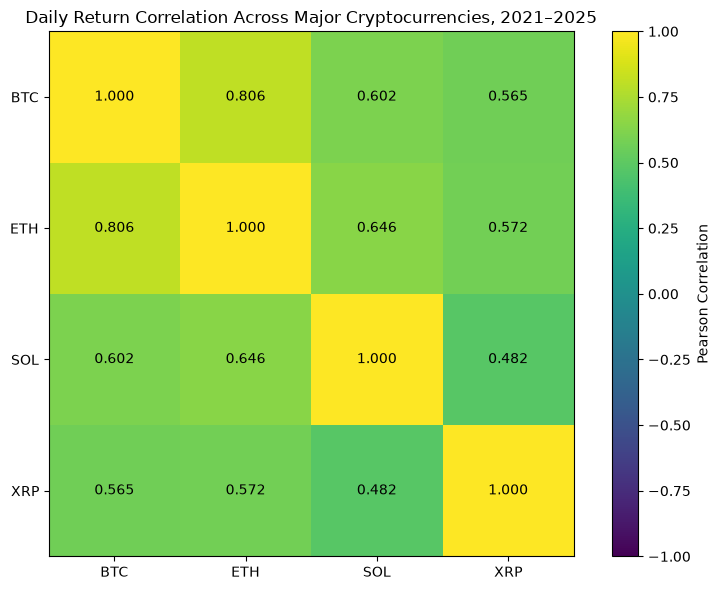

In [114]:
# BTC Return Correlation Heatmap

import matplotlib.pyplot as plt
import numpy as np

corr_matrix = returns_wide[
    ["btc", "eth", "sol", "xrp"]
].corr()

fig, ax = plt.subplots(figsize=(8, 6))

heatmap = ax.imshow(
    corr_matrix,
    vmin=-1,
    vmax=1
)

assets = ["BTC", "ETH", "SOL", "XRP"]

ax.set_xticks(range(len(assets)))
ax.set_yticks(range(len(assets)))
ax.set_xticklabels(assets)
ax.set_yticklabels(assets)

# Add correlation values inside each square
for i in range(len(assets)):
    for j in range(len(assets)):
        ax.text(
            j,
            i,
            f"{corr_matrix.iloc[i, j]:.3f}",
            ha="center",
            va="center"
        )

ax.set_title(
    "Daily Return Correlation Across Major Cryptocurrencies, 2021–2025"
)

fig.colorbar(
    heatmap,
    ax=ax,
    label="Pearson Correlation"
)

plt.tight_layout()

from pathlib import Path

figures_dir = Path.cwd() / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figures_dir / "btc_return_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

print("Saved to:", figures_dir)
plt.show()

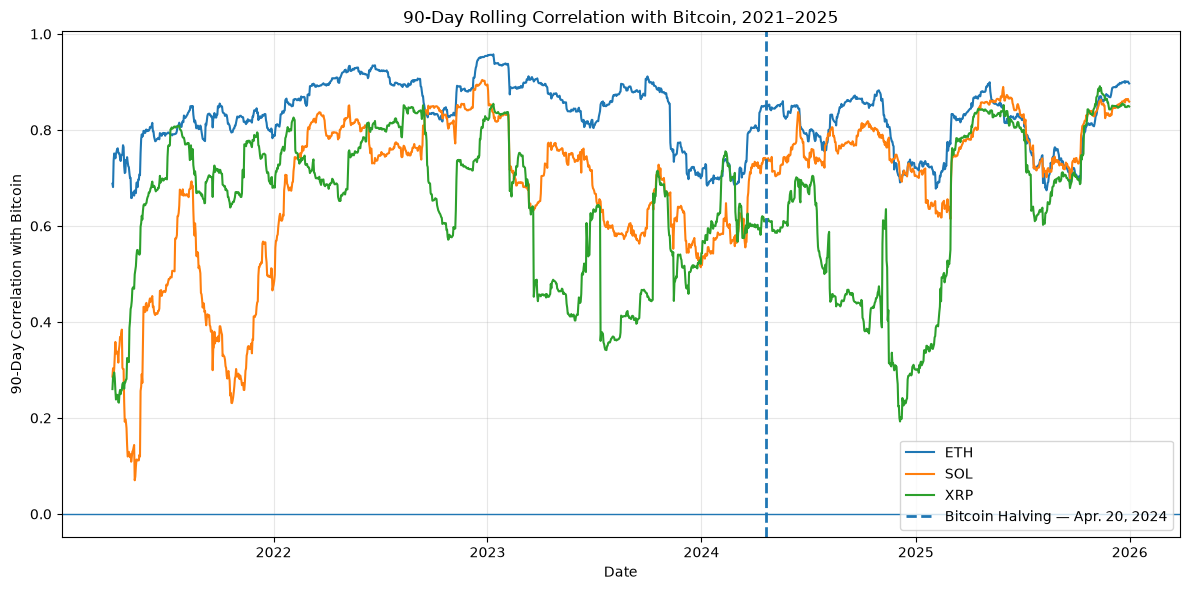

In [115]:
# 90-Day Rolling Correlation with Bitcoin

rolling_corr = pd.DataFrame(
    index=returns_wide.index
)

for asset in ["eth", "sol", "xrp"]:
    rolling_corr[asset] = (
        returns_wide["btc"]
        .rolling(window=90)
        .corr(returns_wide[asset])
    )

plt.figure(figsize=(12, 6))

for asset in ["eth", "sol", "xrp"]:
    plt.plot(
        rolling_corr.index,
        rolling_corr[asset],
        label=asset.upper()
    )

halving_date = pd.Timestamp(
    "2024-04-20",
    tz="UTC"
)

plt.axvline(
    halving_date,
    linestyle="--",
    linewidth=2,
    label="Bitcoin Halving — Apr. 20, 2024"
)

plt.axhline(
    0,
    linewidth=1
)

plt.xlabel("Date")
plt.ylabel("90-Day Correlation with Bitcoin")
plt.title(
    "90-Day Rolling Correlation with Bitcoin, 2021–2025"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    figures_dir / "btc_90day_rolling_correlation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

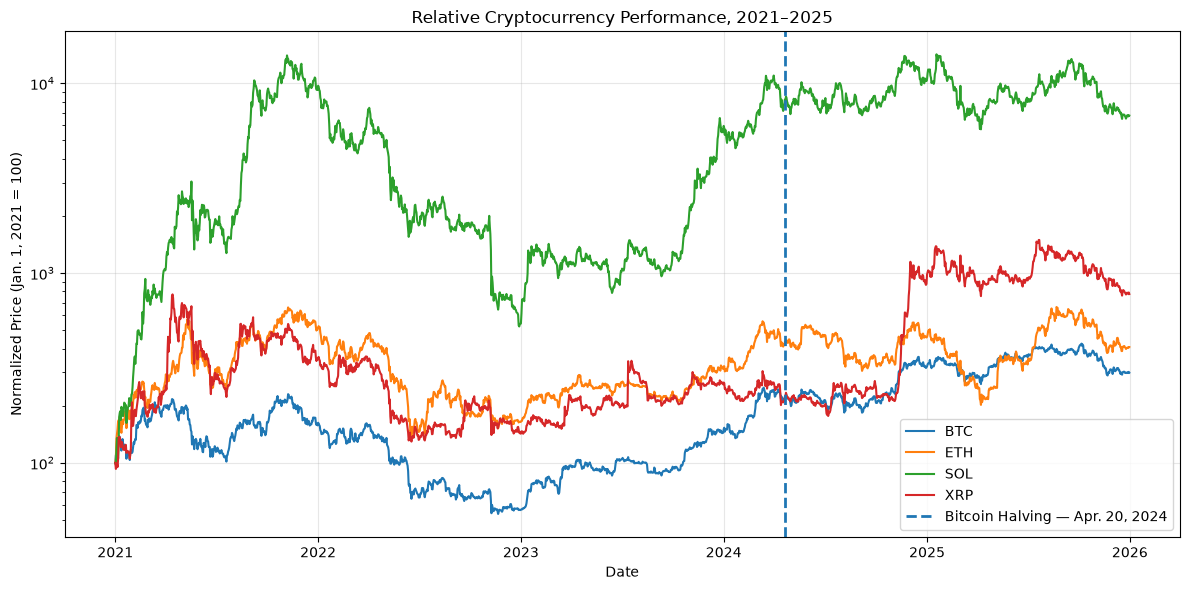

In [116]:
# Normalized cryptocurrency performance, 2021–2025

close_wide = market_clean.pivot(
    index="date",
    columns="asset",
    values="close"
)

normalized_prices = (
    close_wide
    .div(close_wide.iloc[0])
    .mul(100)
)

plt.figure(figsize=(12, 6))

for asset in ["btc", "eth", "sol", "xrp"]:
    plt.plot(
        normalized_prices.index,
        normalized_prices[asset],
        label=asset.upper()
    )

plt.axvline(
    halving_date,
    linestyle="--",
    linewidth=2,
    label="Bitcoin Halving — Apr. 20, 2024"
)

plt.xlabel("Date")
plt.ylabel("Normalized Price (Jan. 1, 2021 = 100)")
plt.title(
    "Relative Cryptocurrency Performance, 2021–2025"
)

plt.yscale("log")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    figures_dir / "crypto_normalized_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

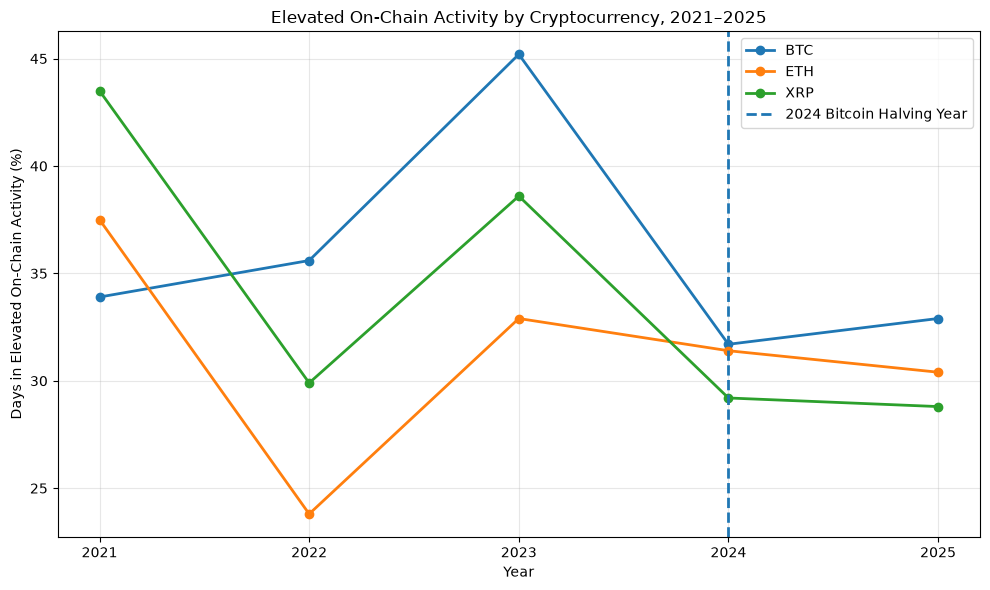

In [119]:
# Elevated On-Chain Activity by year

annual_regime_summary = (
    final_df
    .assign(
        elevated=(
            final_df["regime_label"]
            == "Elevated On-Chain Activity"
        )
    )
    .groupby(["asset", "year"])["elevated"]
    .mean()
    .mul(100)
    .round(1)
    .reset_index(name="percent_elevated")
)

plt.figure(figsize=(10, 6))

for asset in ["btc", "eth", "xrp"]:
    asset_data = annual_regime_summary[
        annual_regime_summary["asset"] == asset
    ]

    plt.plot(
        asset_data["year"],
        asset_data["percent_elevated"],
        marker="o",
        linewidth=2,
        label=asset.upper()
    )

plt.axvline(
    2024,
    linestyle="--",
    linewidth=2,
    label="2024 Bitcoin Halving Year"
)

plt.xlabel("Year")
plt.ylabel("Days in Elevated On-Chain Activity (%)")

plt.title(
    "Elevated On-Chain Activity by Cryptocurrency, 2021–2025"
)

plt.xticks([2021, 2022, 2023, 2024, 2025])
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    figures_dir / "annual_onchain_activity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

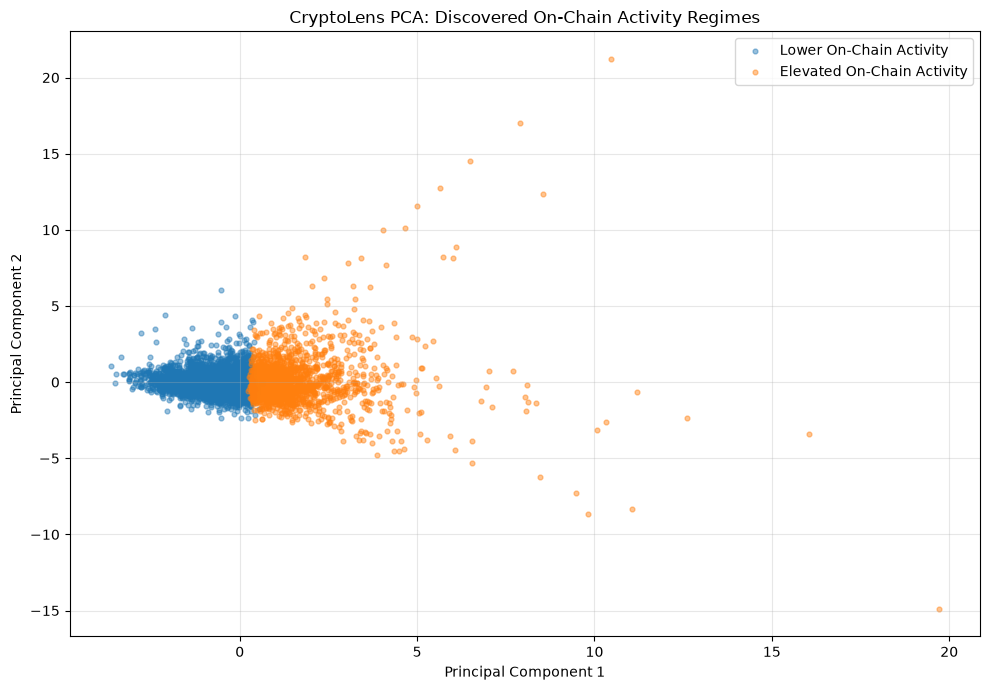

In [118]:
# PCA visualization of discovered on-chain activity regimes

plt.figure(figsize=(10, 7))

for regime in sorted(final_df["regime"].unique()):

    mask = final_df["regime"] == regime

    plt.scatter(
        pca_df_final.loc[mask, "PC1"],
        pca_df_final.loc[mask, "PC2"],
        s=12,
        alpha=0.45,
        label=regime_name_map[regime]
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.title(
    "CryptoLens PCA: Discovered On-Chain Activity Regimes"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    figures_dir / "pca_activity_regimes.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

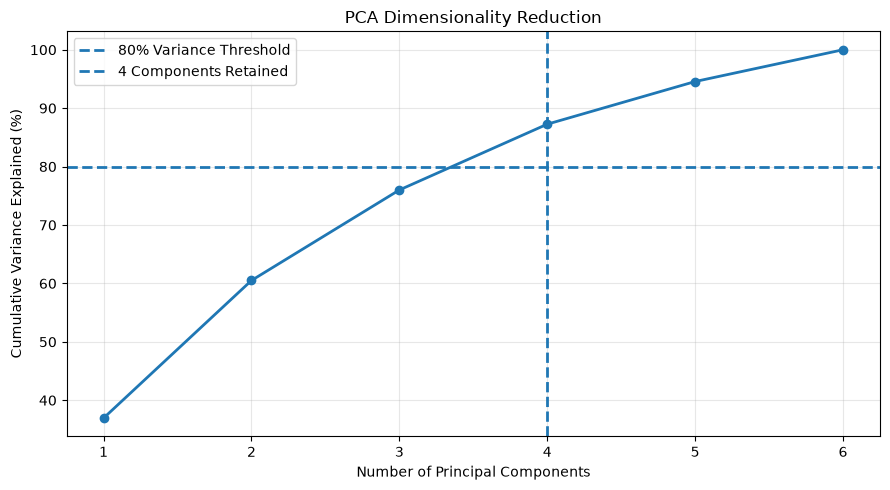

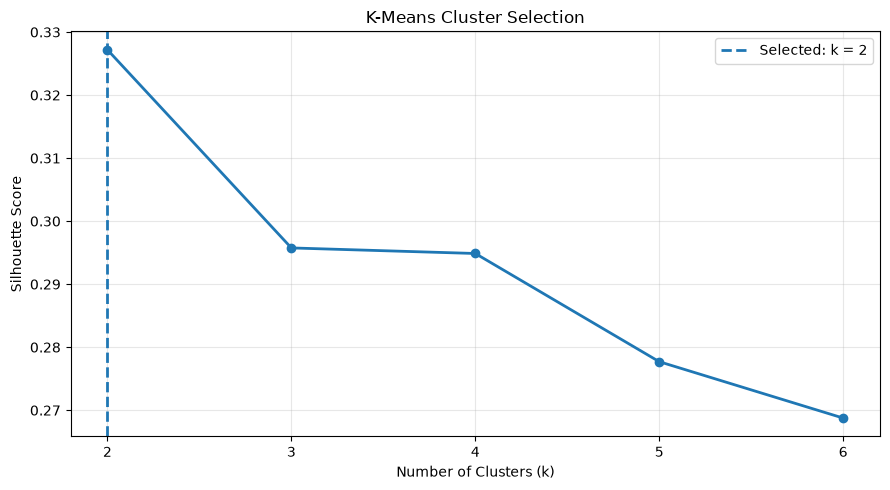

In [121]:
# Visual #6A — PCA Explained Variance

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(final_pca_summary) + 1),
    final_pca_summary["Cumulative Variance"] * 100,
    marker="o",
    linewidth=2
)

plt.axhline(
    80,
    linestyle="--",
    linewidth=2,
    label="80% Variance Threshold"
)

plt.axvline(
    4,
    linestyle="--",
    linewidth=2,
    label="4 Components Retained"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Variance Explained (%)")
plt.title("PCA Dimensionality Reduction")

plt.xticks(range(1, len(final_pca_summary) + 1))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    figures_dir / "pca_variance_explained.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Visual #6B — K-Means Cluster Selection

plt.figure(figsize=(9, 5))

plt.plot(
    final_cluster_results["k"],
    final_cluster_results["silhouette_score"],
    marker="o",
    linewidth=2
)

plt.axvline(
    2,
    linestyle="--",
    linewidth=2,
    label="Selected: k = 2"
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("K-Means Cluster Selection")

plt.xticks(final_cluster_results["k"])
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    figures_dir / "kmeans_cluster_selection.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

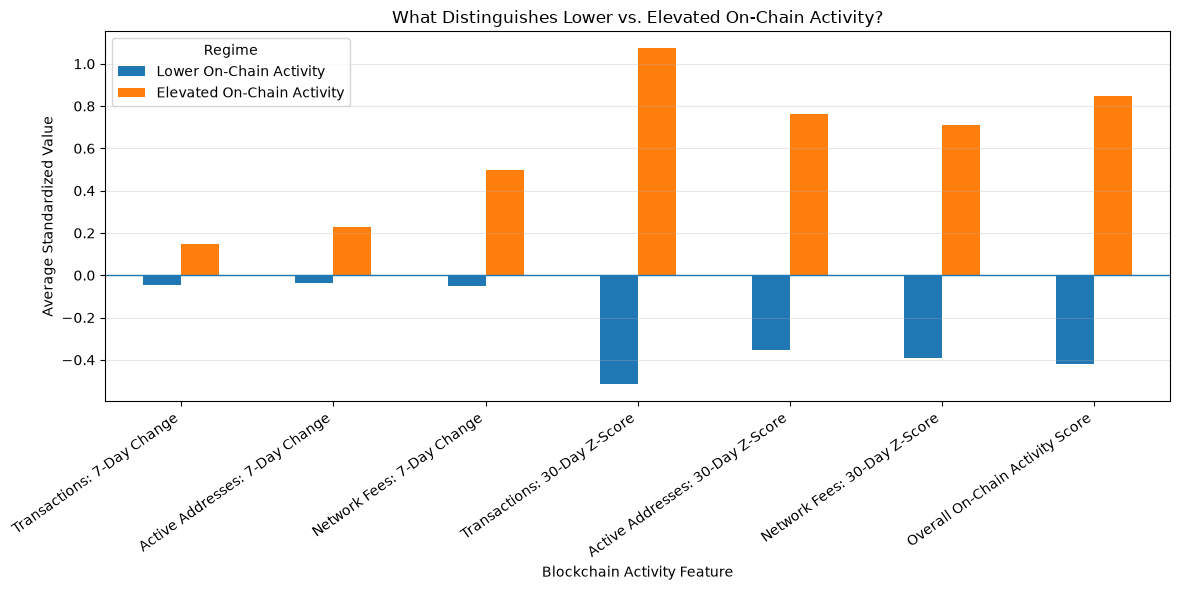

In [122]:
# Regime profile comparison

regime_plot = regime_profile.copy()

regime_plot.index = [
    regime_name_map[i]
    for i in regime_plot.index
]

features_to_plot = [
    "TxCnt_7d_pct_change",
    "AdrActCnt_7d_pct_change",
    "FeeTotNtv_7d_pct_change",
    "TxCnt_30d_z",
    "AdrActCnt_30d_z",
    "FeeTotNtv_30d_z",
    "OnChain_Activity_Score"
]

regime_plot = regime_plot[features_to_plot]

# Make labels easier to read
feature_labels = {
    "TxCnt_7d_pct_change": "Transactions: 7-Day Change",
    "AdrActCnt_7d_pct_change": "Active Addresses: 7-Day Change",
    "FeeTotNtv_7d_pct_change": "Network Fees: 7-Day Change",
    "TxCnt_30d_z": "Transactions: 30-Day Z-Score",
    "AdrActCnt_30d_z": "Active Addresses: 30-Day Z-Score",
    "FeeTotNtv_30d_z": "Network Fees: 30-Day Z-Score",
    "OnChain_Activity_Score": "Overall On-Chain Activity Score"
}

regime_plot = regime_plot.rename(
    columns=feature_labels
)

regime_plot.T.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.axhline(
    0,
    linewidth=1
)

plt.xlabel("Blockchain Activity Feature")
plt.ylabel("Average Standardized Value")

plt.title(
    "What Distinguishes Lower vs. Elevated On-Chain Activity?"
)

plt.xticks(
    rotation=35,
    ha="right"
)

plt.legend(
    title="Regime"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.savefig(
    figures_dir / "regime_profile_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

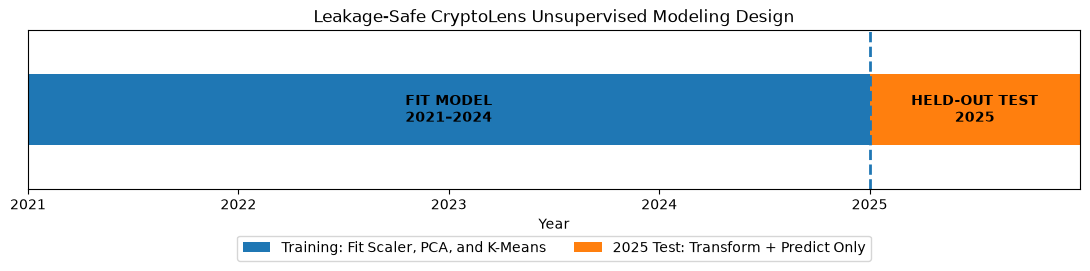

In [123]:
# Leakage-Safe Train/Test Timeline

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(11, 3))

# Training period
ax.barh(
    y=1,
    width=4,
    left=2021,
    height=0.45,
    label="Training: Fit Scaler, PCA, and K-Means"
)

# Testing period
ax.barh(
    y=1,
    width=1,
    left=2025,
    height=0.45,
    label="2025 Test: Transform + Predict Only"
)

ax.axvline(
    2025,
    linestyle="--",
    linewidth=2
)

ax.text(
    2023,
    1,
    "FIT MODEL\n2021–2024",
    ha="center",
    va="center",
    fontweight="bold"
)

ax.text(
    2025.5,
    1,
    "HELD-OUT TEST\n2025",
    ha="center",
    va="center",
    fontweight="bold"
)

ax.set_xlim(2021, 2026)
ax.set_ylim(0.5, 1.5)

ax.set_xticks(
    [2021, 2022, 2023, 2024, 2025]
)

ax.set_yticks([])

ax.set_xlabel("Year")

ax.set_title(
    "Leakage-Safe CryptoLens Unsupervised Modeling Design"
)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.25),
    ncol=2
)

plt.tight_layout()
plt.savefig(
    figures_dir / "leakage_safe_timeline.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

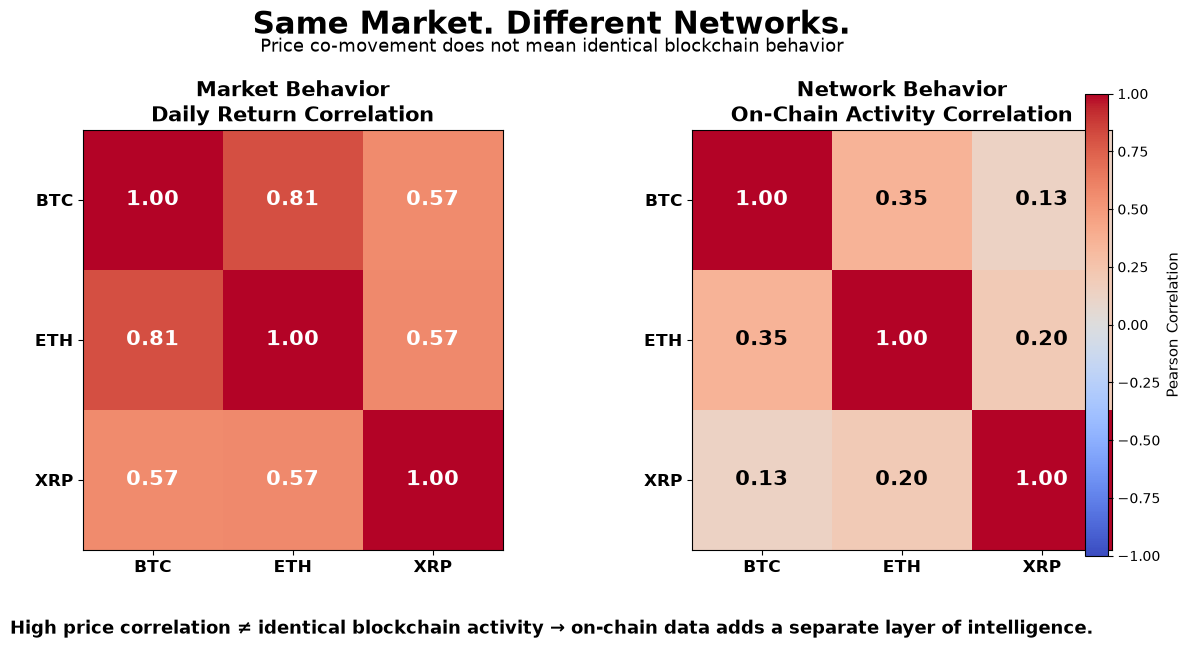

In [125]:
# ============================================================
# FINAL SYNTHESIS VISUAL
# Same Market. Different Networks.
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# 1. PRICE RETURN CORRELATIONS
# -----------------------------
price_assets = ["btc", "eth", "xrp"]

price_corr = (
    returns_wide[price_assets]
    .corr()
)

price_corr.index = ["BTC", "ETH", "XRP"]
price_corr.columns = ["BTC", "ETH", "XRP"]


# -----------------------------
# 2. ON-CHAIN ACTIVITY CORRELATIONS
# -----------------------------
onchain_wide = final_df.pivot(
    index="time",
    columns="asset",
    values="OnChain_Activity_Score"
)

onchain_corr = (
    onchain_wide[["btc", "eth", "xrp"]]
    .corr()
)

onchain_corr.index = ["BTC", "ETH", "XRP"]
onchain_corr.columns = ["BTC", "ETH", "XRP"]


# -----------------------------
# 3. BUILD COMPARISON FIGURE
# -----------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

fig.suptitle(
    "Same Market. Different Networks.",
    fontsize=22,
    fontweight="bold",
    y=1.02
)

fig.text(
    0.5,
    0.95,
    "Price co-movement does not mean identical blockchain behavior",
    ha="center",
    fontsize=13
)

vmin = -1
vmax = 1

im1 = axes[0].imshow(price_corr, vmin=vmin, vmax=vmax, cmap="coolwarm")
axes[0].set_title(
    "Market Behavior\nDaily Return Correlation",
    fontsize=15,
    fontweight="bold"
)

im2 = axes[1].imshow(onchain_corr, vmin=vmin, vmax=vmax, cmap="coolwarm")
axes[1].set_title(
    "Network Behavior\nOn-Chain Activity Correlation",
    fontsize=15,
    fontweight="bold"
)

labels = ["BTC", "ETH", "XRP"]

for ax, matrix in zip(axes, [price_corr, onchain_corr]):
    ax.set_xticks(range(3))
    ax.set_yticks(range(3))
    ax.set_xticklabels(labels, fontsize=12, fontweight="bold")
    ax.set_yticklabels(labels, fontsize=12, fontweight="bold")

    for i in range(3):
        for j in range(3):
            value = matrix.iloc[i, j]
            text_color = "white" if abs(value) > 0.55 else "black"

            ax.text(
                j,
                i,
                f"{value:.2f}",
                ha="center",
                va="center",
                fontsize=15,
                fontweight="bold",
                color=text_color
            )

cbar = fig.colorbar(
    im2,
    ax=axes,
    fraction=0.025,
    pad=0.04
)
cbar.set_label("Pearson Correlation", fontsize=11)

fig.text(
    0.5,
    -0.02,
    "High price correlation ≠ identical blockchain activity → on-chain data adds a separate layer of intelligence.",
    ha="center",
    fontsize=13,
    fontweight="bold"
)

plt.subplots_adjust(top=0.82, bottom=0.12, wspace=0.28)

plt.savefig(
    figures_dir / "market_vs_network_correlation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

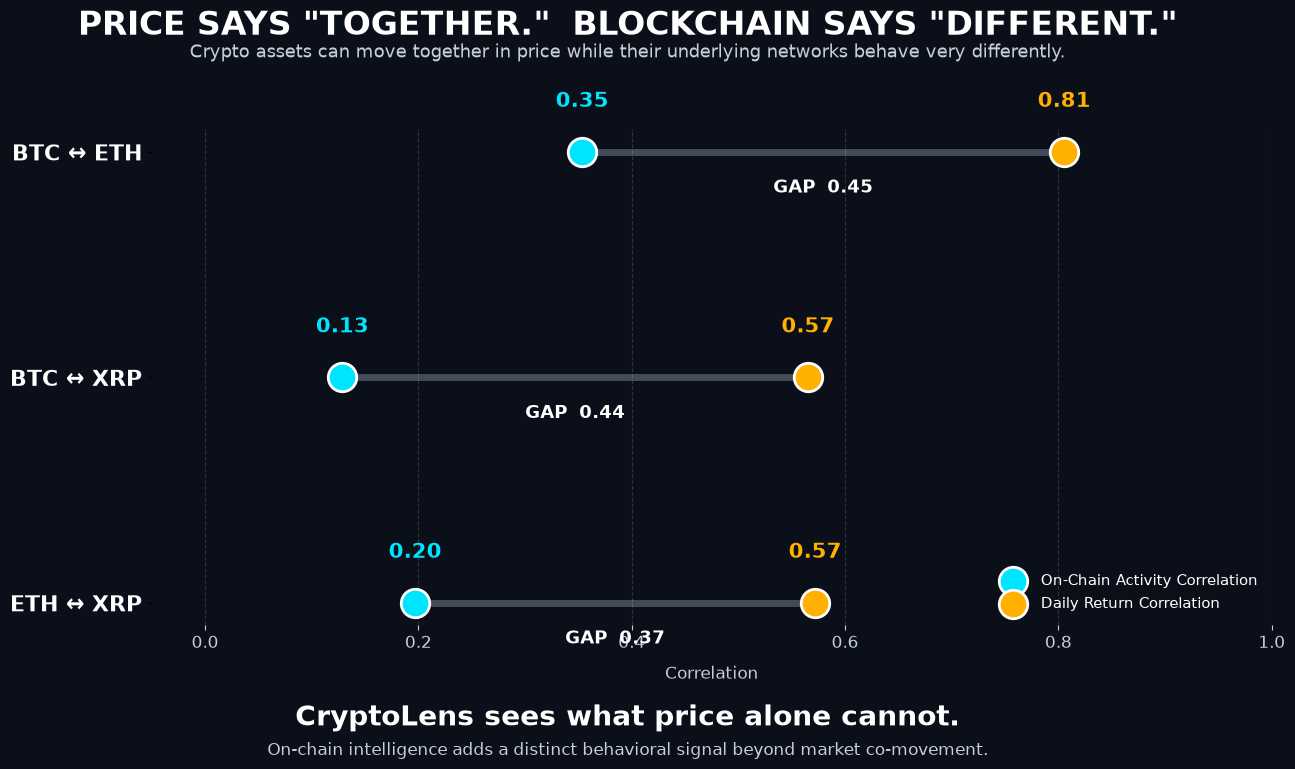

In [128]:
# ============================================================
# FINAL HERO VISUAL
# Price Says "Together." Blockchain Says "Different."
# ============================================================

import matplotlib.pyplot as plt
import numpy as np


# ------------------------------------------------------------
# 1. DATA
# ------------------------------------------------------------

pairs = ["BTC ↔ ETH", "BTC ↔ XRP", "ETH ↔ XRP"]

market_corr = np.array([
    price_corr.loc["BTC", "ETH"],
    price_corr.loc["BTC", "XRP"],
    price_corr.loc["ETH", "XRP"]
])

network_corr = np.array([
    onchain_corr.loc["BTC", "ETH"],
    onchain_corr.loc["BTC", "XRP"],
    onchain_corr.loc["ETH", "XRP"]
])

gap = market_corr - network_corr

y = np.arange(len(pairs))


# ------------------------------------------------------------
# 2. FIGURE
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 8))

fig.patch.set_facecolor("#0B0F19")
ax.set_facecolor("#0B0F19")


# ------------------------------------------------------------
# 3. CONNECTION LINES
# ------------------------------------------------------------

for i in range(len(pairs)):

    ax.plot(
        [network_corr[i], market_corr[i]],
        [y[i], y[i]],
        color="#5B6475",
        linewidth=5,
        alpha=0.7,
        zorder=1
    )


# ------------------------------------------------------------
# 4. DATA POINTS
# ------------------------------------------------------------

ax.scatter(
    network_corr,
    y,
    s=420,
    color="#00E5FF",
    edgecolor="white",
    linewidth=2,
    label="On-Chain Activity Correlation",
    zorder=3
)

ax.scatter(
    market_corr,
    y,
    s=420,
    color="#FFB000",
    edgecolor="white",
    linewidth=2,
    label="Daily Return Correlation",
    zorder=3
)


# ------------------------------------------------------------
# 5. VALUE + GAP LABELS
# ------------------------------------------------------------

for i in range(len(pairs)):

    ax.text(
        network_corr[i],
        y[i] - 0.20,
        f"{network_corr[i]:.2f}",
        color="#00E5FF",
        fontsize=15,
        fontweight="bold",
        ha="center"
    )

    ax.text(
        market_corr[i],
        y[i] - 0.20,
        f"{market_corr[i]:.2f}",
        color="#FFB000",
        fontsize=15,
        fontweight="bold",
        ha="center"
    )

    ax.text(
        (network_corr[i] + market_corr[i]) / 2,
        y[i] + 0.18,
        f"GAP  {gap[i]:.2f}",
        color="white",
        fontsize=13,
        fontweight="bold",
        ha="center"
    )


# ------------------------------------------------------------
# 6. AXES
# ------------------------------------------------------------

ax.set_yticks(y)

ax.set_yticklabels(
    pairs,
    fontsize=16,
    fontweight="bold",
    color="white"
)

ax.set_xlim(-0.05, 1.0)

ax.set_xticks(np.arange(0, 1.01, 0.2))

ax.tick_params(
    axis="x",
    colors="#C7CEDB",
    labelsize=12
)

ax.set_xlabel(
    "Correlation",
    fontsize=12,
    color="#C7CEDB",
    labelpad=10
)

ax.invert_yaxis()

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.15,
    color="white"
)

for spine in ax.spines.values():
    spine.set_visible(False)


# ------------------------------------------------------------
# 7. TITLE
# ------------------------------------------------------------

fig.suptitle(
    'PRICE SAYS "TOGETHER."  BLOCKCHAIN SAYS "DIFFERENT."',
    fontsize=24,
    fontweight="bold",
    color="white",
    y=0.97
)

fig.text(
    0.5,
    0.91,
    "Crypto assets can move together in price while their underlying networks behave very differently.",
    ha="center",
    fontsize=13,
    color="#C7CEDB"
)


# ------------------------------------------------------------
# 8. LEGEND
# ------------------------------------------------------------

legend = ax.legend(
    loc="lower right",
    frameon=False,
    fontsize=11
)

for text in legend.get_texts():
    text.set_color("white")


# ------------------------------------------------------------
# 9. BOTTOM TAKEAWAY
# ------------------------------------------------------------

fig.text(
    0.5,
    0.075,
    "CryptoLens sees what price alone cannot.",
    ha="center",
    fontsize=20,
    fontweight="bold",
    color="white"
)

fig.text(
    0.5,
    0.038,
    "On-chain intelligence adds a distinct behavioral signal beyond market co-movement.",
    ha="center",
    fontsize=12,
    color="#C7CEDB"
)


# ------------------------------------------------------------
# 10. LAYOUT
# ------------------------------------------------------------

plt.subplots_adjust(
    top=0.82,
    bottom=0.20,
    left=0.16,
    right=0.96
)


# ------------------------------------------------------------
# 11. SAVE
# ------------------------------------------------------------

plt.savefig(
    figures_dir / "cryptolens_hero_market_vs_blockchain.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)


# ------------------------------------------------------------
# 12. DISPLAY
# ------------------------------------------------------------

plt.show()

In [130]:
git clone -b yourname-branch https://github.com/AustinB2319/DS6021-Final-Project.git
cd DS6021-Final-Project

SyntaxError: invalid syntax (2148197846.py, line 1)